# YOLOX-S-Lite: 15 more epochs (same lr 3e-4) + everything at confidence 0.40 — Colab GPU

- **Starts from** the finished 5-epoch run `checkpoints/s_lite_e5_v1/best.pth` (only read).
- **Training:** 15 epochs, batch 16, AdamW **lr 3e-4** (same as the 5-epoch run; schedule restarts), 200-update warmup, cosine to 0.1×, EMA; checkpoint every
  250 batches to Drive; early stop if monitor AP50:95 does not improve for 5 epochs.
- **Reporting:** baseline, S-Lite 5 epochs and S-Lite 5+15 epochs, all on Kaggle val/test at confidence **0.40**, fixed in
  advance (not tuned on any split). New outputs only: `checkpoints/s_lite_e5p15_v1/`, `logs/e5p15/`,
  `validation|test/*_c040/`, `exports/s_lite_e20/`, `plots/e5p15/`, `reports_e20/`. Today's `reports/` stays as it is.

**Run (T4 GPU):** Cell 1 → Cell 2 → Cell 3 any time → Cell 4 when the log says `PIPELINE E5P15 COMPLETE`.
**After a disconnect:** Cell 1, then Cell 2: it verifies `last.pth` and resumes.

## Cell 1 — Setup and checks

In [ ]:
REPO = '/content/honeywell'
DRIVE_EXP = '/content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame'
LOG = f'{DRIVE_EXP}/logs/e5p15/pipeline.log'
PID = f'{DRIVE_EXP}/logs/e5p15/pipeline.pid'
KAGGLE_ID = 'yuulind/fasdd-cv-coco'
EXPECTED = {'train': 63546, 'val': 15884, 'test': 15884}
DRIVE_DATASET = '/content/drive/MyDrive/HoneywellTraining/datasets/fasdd-cv-coco'   # optional verified copy
BASELINE_CANDIDATES = ['/content/drive/MyDrive/HoneywellTraining/full_v1/best.pth']  # add the path if yours differs
PY = '/content/venv/bin/python'
CHECKPOINT = f'{REPO}/experiments/yolox_s_lite_flame/pretrained/yolox_s_ti_lite_coco.pth'
CHECKPOINT_URL = 'http://software-dl.ti.com/jacinto7/esd/modelzoo/latest/models/vision/detection/coco/edgeai-yolox/yolox-s-ti-lite_39p1_57p9_checkpoint.pth'
CHECKPOINT_SHA256 = 'd29abb5f1045f64038c159d00760b442aa86403f1f8d4725244e5428ff1b6308'
import os, json, shutil, hashlib, subprocess, urllib.request, platform

def run(command):
    result = subprocess.run(command, shell=True, capture_output=True, text=True)
    if result.returncode:
        print(result.stdout[-3000:], result.stderr[-3000:]); raise RuntimeError(f'failed: {command}')
    return result.stdout.strip()

# 1. GPU / environment
print('notebook python', platform.python_version())
print('GPU:', run('nvidia-smi --query-gpu=name,memory.total,memory.used,driver_version --format=csv,noheader'))
print('CPUs:', os.cpu_count(), '| /content free GiB:', round(shutil.disk_usage('/content').free / 2**30, 1))

# 2. Google Drive mounted and writable
from google.colab import drive
try:
    drive.mount('/content/drive')
except Exception as first_error:
    print('Drive mount failed once (', str(first_error)[:120], '); retrying with force_remount ...')
    try:
        drive.mount('/content/drive', force_remount=True)
    except Exception as error:
        raise SystemExit(f'Drive could not be mounted ({str(error)[:200]}). Run this cell again; if it keeps failing, '
                         'open this notebook in Colab in Chrome. Training progress on Drive is safe.')
for folder in ('checkpoints', 'logs', 'configs', 'validation', 'test', 'plots', 'exports', 'reports'):
    os.makedirs(f'{DRIVE_EXP}/{folder}', exist_ok=True)
probe = f'{DRIVE_EXP}/logs/.write_test'
open(probe, 'w').write('ok'); assert open(probe).read() == 'ok'; os.remove(probe)
print('Drive writable:', DRIVE_EXP)

# 3. Code: baseline repository (public main) + experiment files, rewritten every run
if not os.path.isdir(REPO):
    run(f'git clone -q https://github.com/Skandakm29/honeywell_bmsce_flame_detection.git {REPO}')
print('repository:', run(f'git -C {REPO} log -1 --oneline'))
FILES = {'scripts/evaluate.py': '"""Evaluate a saved checkpoint on a frozen validation manifest and collect failures for review.\n\nThe held-out test split is deliberately not selectable: it stays unused during tuning\n(docs/PROJECT_STATUS.md). Matching follows train.operating_metrics: one-to-one,\nscore-ordered, IoU 0.5, single flame class.\n"""\nimport argparse\nimport contextlib\nimport hashlib\nimport io\nimport json\nimport math\nimport random\nimport time\n\nimport cv2\nimport numpy as np\nimport torch\nfrom torch.utils.data import DataLoader\nfrom flame_model import FlameDetector, ROOT\nfrom train import Flames, collate, configure_worker, detections, operating_metrics\n\n# Flame size as sqrt(box area) in model-input pixels, i.e. after the letterbox resize.\n# COCO\'s small/medium/large use original-image pixels, which mislead for 10k-pixel sources.\nSIZE_BUCKETS = [(\'<8px\',0,8),(\'8-16px\',8,16),(\'16-32px\',16,32),(\'32-64px\',32,64),(\'>=64px\',64,math.inf)]\n\n\ndef size_bucket(side):\n    return next(name for name,low,high in SIZE_BUCKETS if low<=side<high)\n\n\ndef iou(xywh,box):\n    x,y,w,h = xywh\n    a,b,c,d = box\n    intersection = max(0,min(x+w,c)-max(x,a))*max(0,min(y+h,d)-max(y,b))\n    union = w*h+(c-a)*(d-b)-intersection\n    return intersection/union if union>0 else 0\n\n\ndef match(boxes,candidates,threshold):\n    """Same rule as train.operating_metrics; also returns which boxes/predictions failed."""\n    matched = [False]*len(boxes)\n    outcomes = []\n    for prediction in sorted((p for p in candidates if p[\'score\']>=threshold),key=lambda p:-p[\'score\']):\n        best_iou,best_index = 0,None\n        for index,box in enumerate(boxes):\n            if matched[index]:\n                continue\n            overlap = iou(prediction[\'bbox\'],box)\n            if overlap>best_iou:\n                best_iou,best_index = overlap,index\n        hit = best_index is not None and best_iou>=.5\n        if hit:\n            matched[best_index] = True\n        outcomes.append((prediction,hit))\n    return matched,outcomes\n\n\ndef false_detection_kind(prediction,boxes):\n    if not boxes:\n        return \'negative_image\'\n    overlap = max(iou(prediction[\'bbox\'],box) for box in boxes)\n    if overlap>=.5:\n        return \'duplicate\'\n    if overlap>=.1:\n        return \'poor_localisation\'\n    return \'background_on_flame_image\'\n\n\ndef coco_metrics(records,predictions):\n    from pycocotools.coco import COCO\n    from pycocotools.cocoeval import COCOeval\n    gt = COCO()\n    images,annotations = [],[]\n    for i,record in enumerate(records):\n        images.append({\'id\':i,\'width\':record[\'width\'],\'height\':record[\'height\']})\n        for x,y,x2,y2 in record[\'boxes\']:\n            annotations.append({\'id\':len(annotations)+1,\'image_id\':i,\'category_id\':1,\n                                \'bbox\':[x,y,x2-x,y2-y],\'area\':(x2-x)*(y2-y),\'iscrowd\':0})\n    gt.dataset = {\'info\':{},\'images\':images,\'annotations\':annotations,\'categories\':[{\'id\':1,\'name\':\'flame\'}]}\n    gt.createIndex()\n    if not predictions:\n        return {\'AP50_95\':0.0,\'AP50\':0.0}\n    with contextlib.redirect_stdout(io.StringIO()):\n        evaluation = COCOeval(gt,gt.loadRes(predictions),\'bbox\')\n        evaluation.evaluate()\n        evaluation.accumulate()\n        evaluation.summarize()\n    names = [\'AP50_95\',\'AP50\',\'AP75\',\'AP_small\',\'AP_medium\',\'AP_large\',\'AR1\',\'AR10\',\'AR100\']\n    return {name:float(value) for name,value in zip(names,evaluation.stats)}\n\n\ndef contact_sheets(items,records,predictions_by_image,confidence,stem,directory,per_sheet=25,columns=5):\n    """Green=label, red=prediction at the operating confidence, yellow=the reviewed failure."""\n    for page in range(0,len(items),per_sheet):\n        tiles = []\n        for item in items[page:page+per_sheet]:\n            record = records[item[\'image_index\']]\n            image = cv2.imread(str(ROOT/record[\'image\']))\n            thickness = max(2,round(max(image.shape[:2])/300))\n            for box in record[\'boxes\']:\n                cv2.rectangle(image,tuple(map(int,box[:2])),tuple(map(int,box[2:])),(0,255,0),thickness)\n            for prediction in predictions_by_image[item[\'image_index\']]:\n                if prediction[\'score\']>=confidence:\n                    x,y,w,h = map(int,prediction[\'bbox\'])\n                    cv2.rectangle(image,(x,y),(x+w,y+h),(0,0,255),thickness)\n            x,y,x2,y2 = map(int,item[\'box_xyxy\'])\n            cv2.rectangle(image,(x,y),(x2,y2),(0,255,255),thickness*2)\n            ratio = min(320/image.shape[1],240/image.shape[0])\n            resized = cv2.resize(image,(max(1,int(image.shape[1]*ratio)),max(1,int(image.shape[0]*ratio))))\n            tile = np.zeros((260,320,3),np.uint8)\n            tile[20:20+resized.shape[0],:resized.shape[1]] = resized\n            cv2.putText(tile,item[\'caption\'],(4,14),cv2.FONT_HERSHEY_SIMPLEX,.4,(255,255,255),1)\n            tiles.append(tile)\n        while len(tiles)%columns:\n            tiles.append(np.zeros_like(tiles[0]))\n        rows = [np.hstack(tiles[i:i+columns]) for i in range(0,len(tiles),columns)]\n        cv2.imwrite(str(directory/f\'{stem}_{page//per_sheet+1:02d}.jpg\'),np.vstack(rows))\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--checkpoint\',required=True,help=\'best.pth (or last.pth) from a training run\')\n    parser.add_argument(\'--data\',default=\'data/fasdd\')\n    parser.add_argument(\'--split\',choices=[\'val\',\'validation_full\'],default=\'validation_full\',\n                        help=\'Held-out test is deliberately not selectable during tuning\')\n    parser.add_argument(\'--output\',required=True)\n    parser.add_argument(\'--size\',type=int,default=416,help=\'Must match the training run\')\n    parser.add_argument(\'--batch\',type=int,default=32)\n    parser.add_argument(\'--workers\',type=int,default=2)\n    parser.add_argument(\'--confidence\',type=float,default=.4,help=\'Operating point for the failure breakdown\')\n    parser.add_argument(\'--review\',type=int,default=100,help=\'Misses and false detections sampled for human review\')\n    parser.add_argument(\'--device\',choices=[\'auto\',\'cpu\',\'cuda\'],default=\'auto\')\n    args = parser.parse_args()\n    device = torch.device(\'cuda\' if args.device==\'auto\' and torch.cuda.is_available() else (\'cpu\' if args.device==\'auto\' else args.device))\n    output = ROOT/args.output\n    output.mkdir(parents=True,exist_ok=True)\n    checkpoint = ROOT/args.checkpoint\n    model = FlameDetector()\n    model.load_state_dict(torch.load(checkpoint,map_location=\'cpu\',weights_only=True)[\'model\'])\n    model.to(device).eval()\n    manifest = ROOT/args.data/f\'{args.split}.json\'\n    dataset = Flames(manifest,args.size)\n    records = dataset.records\n    worker_options = {\'multiprocessing_context\':\'spawn\'} if args.workers else {}\n    loader = DataLoader(dataset,batch_size=args.batch,collate_fn=collate,num_workers=args.workers,\n                        worker_init_fn=configure_worker,pin_memory=device.type==\'cuda\',**worker_options)\n    predictions = []\n    start = time.perf_counter()\n    with torch.inference_mode():\n        for done,(images,_,indices) in enumerate(loader,1):\n            outputs = model(images.to(device)).cpu()\n            for prediction,index in zip(outputs,indices):\n                boxes,scores = detections(prediction,records[index],dataset.size)\n                for (x,y,x2,y2),score in zip(boxes.tolist(),scores.tolist()):\n                    predictions.append({\'image_id\':index,\'category_id\':1,\'bbox\':[x,y,x2-x,y2-y],\'score\':score})\n            if done%50==0 or done==len(loader):\n                elapsed = time.perf_counter()-start\n                print(f\'batch {done}/{len(loader)}, eta_min={elapsed/done*(len(loader)-done)/60:.1f}\',flush=True)\n    metrics = coco_metrics(records,predictions)\n    print(json.dumps(metrics),flush=True)\n    by_image = [[] for _ in records]\n    for prediction in predictions:\n        by_image[prediction[\'image_id\']].append(prediction)\n    sizes = {name:{\'boxes\':0,\'detected\':0} for name,_,_ in SIZE_BUCKETS}\n    kinds = {}\n    misses,false_detections = [],[]\n    for index,record in enumerate(records):\n        ratio = min(args.size/record[\'height\'],args.size/record[\'width\'])\n        matched,outcomes = match(record[\'boxes\'],by_image[index],args.confidence)\n        for box,hit in zip(record[\'boxes\'],matched):\n            side = math.sqrt((box[2]-box[0])*(box[3]-box[1]))*ratio\n            bucket = size_bucket(side)\n            sizes[bucket][\'boxes\'] += 1\n            sizes[bucket][\'detected\'] += hit\n            if not hit:\n                misses.append({\'image_index\':index,\'image\':record[\'image\'],\'box_xyxy\':box,\n                               \'input_side_px\':round(side,1),\'caption\':f\'miss {bucket} #{index}\'})\n        for prediction,hit in outcomes:\n            if hit:\n                continue\n            kind = false_detection_kind(prediction,record[\'boxes\'])\n            kinds[kind] = kinds.get(kind,0)+1\n            x,y,w,h = prediction[\'bbox\']\n            false_detections.append({\'image_index\':index,\'image\':record[\'image\'],\'box_xyxy\':[x,y,x+w,y+h],\n                                     \'score\':round(prediction[\'score\'],3),\'kind\':kind,\n                                     \'caption\':f\'{kind} {prediction["score"]:.2f} #{index}\'})\n    for row in sizes.values():\n        row[\'recall\'] = row[\'detected\']/row[\'boxes\'] if row[\'boxes\'] else None\n    sampler = random.Random(42)\n    review_misses = sampler.sample(misses,min(args.review,len(misses)))\n    review_false = sampler.sample(false_detections,min(args.review,len(false_detections)))\n    contact_sheets(review_misses,records,by_image,args.confidence,\'review_misses\',output)\n    contact_sheets(review_false,records,by_image,args.confidence,\'review_false_detections\',output)\n    summary = {\n        \'checkpoint\':str(args.checkpoint),\n        \'checkpoint_sha256\':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),\n        \'split\':args.split,\'manifest_sha256\':hashlib.sha256(manifest.read_bytes()).hexdigest(),\n        \'size\':args.size,\'images\':len(records),\'flame_boxes\':sum(len(r[\'boxes\']) for r in records),\n        \'negative_images\':sum(not r[\'boxes\'] for r in records),\'device\':str(device),\n        \'coco\':metrics,\n        \'coco_area_note\':\'AP_small/medium/large use original-image pixel areas; see recall_by_input_size for model-input scale\',\n        \'at_confidence\':{\'confidence\':args.confidence,\'misses\':len(misses),\'false_detections\':len(false_detections),\n                         \'false_detections_by_kind\':kinds,\'recall_by_input_size\':sizes},\n        \'threshold_sweep\':operating_metrics(records,predictions),\n        \'evaluation_seconds\':time.perf_counter()-start}\n    (output/\'summary.json\').write_text(json.dumps(summary,indent=2))\n    (output/\'review_misses.json\').write_text(json.dumps(review_misses,indent=2))\n    (output/\'review_false_detections.json\').write_text(json.dumps(review_false,indent=2))\n    # Keep the dump reviewable in size; AP above used every prediction down to 0.001.\n    (output/\'predictions_ge_0.05.json\').write_text(json.dumps([p for p in predictions if p[\'score\']>=.05]))\n    print(json.dumps({k:summary[k] for k in (\'coco\',\'at_confidence\')},indent=2),flush=True)\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/s_model.py': '"""YOLOX-S-ti-lite with a one-class flame head, built from the same pinned TI modules as the baseline.\n\nFlags match exps/default/yolox_s_ti_lite.py at cbdd9d85def4e55e3fbbf38c155e183e90ed5cc6:\ndepth 0.33, width 0.50, ReLU, convolutional stem, split max-pooling, regular convolutions.\nOnly the width differs from the baseline FlameDetector (0.25), so forward/loss are inherited.\n"""\nimport importlib\nimport sys\nfrom pathlib import Path\n\nfrom torch import nn\n\nROOT = Path(__file__).resolve().parents[2]\nsys.path.insert(0, str(ROOT/\'scripts\'))\nfrom flame_model import FlameDetector, load_vendor  # noqa: E402\n\nARCHITECTURE = \'TI YOLOX-S-ti-lite\'\n\n\nclass SFlameDetector(FlameDetector):\n    def __init__(self):\n        nn.Module.__init__(self)\n        load_vendor()\n        backbone = importlib.import_module(\'yolox.models.yolo_pafpn\').YOLOPAFPN\n        head = importlib.import_module(\'yolox.models.yolo_head\').YOLOXHead\n        self.backbone = backbone(.33,.5,in_channels=[256,512,1024],act=\'relu\',depthwise=False,\n                                 conv_focus=True,split_max_pool_kernel=True)\n        self.head = head(1,.5,in_channels=[256,512,1024],act=\'relu\',depthwise=False)\n        for layer in self.modules():\n            if isinstance(layer, nn.BatchNorm2d):\n                layer.eps = 1e-3\n                layer.momentum = .03\n        self.head.initialize_biases(1e-2)\n\n\ndef build(arch):\n    """\'nano\' is the unchanged baseline model; \'s\' is this experiment\'s model."""\n    return {\'nano\':FlameDetector,\'s\':SFlameDetector}[arch]()\n', 'experiments/yolox_s_lite_flame/prepare_kaggle.py': '"""Build manifests from the Kaggle FASDD-CV-COCO copy, keeping its own train/val/test splits.\n\nReads <root>/annotations/{train,val,test}.json and <root>/images/; never writes there.\nOnly \'fire\' boxes become flame targets. Smoke annotations are ignored, so smoke-only images\nand images without annotations are negatives (no boxes). Records use the format read by\nscripts/train.py: absolute image path, width, height, [x1,y1,x2,y2] boxes in original pixels.\n\nImages are quarantined (reported, left out of the manifest) when the file is missing, its\nheader size differs from the annotation, it has an EXIF orientation tag and cv2 (which applies\nvalid rotations) decodes it at a different size, which train.Flames would reject, or a box\nfails the baseline audit rule (validated_boxes).\nExact duplicates across splits are reported, not removed.\n"""\nimport argparse\nimport collections\nimport concurrent.futures\nimport hashlib\nimport json\nimport math\nimport random\nimport sys\nfrom pathlib import Path\n\nimport cv2\nfrom PIL import Image\n\nROOT = Path(__file__).resolve().parents[2]\nsys.path.insert(0, str(ROOT/\'scripts\'))\nfrom audit_local import validated_boxes  # noqa: E402\n\nSPLITS = (\'train\',\'val\',\'test\')\nCOCO_AREAS = [(\'small\',0,32**2),(\'medium\',32**2,96**2),(\'large\',96**2,math.inf)]\nINPUT_SIDES = [(\'<8px\',0,8),(\'8-16px\',8,16),(\'16-32px\',16,32),(\'32-64px\',32,64),(\'>=64px\',64,math.inf)]\n\n\ndef bucket(value,table):\n    return next(name for name,low,high in table if low<=value<high)\n\n\ndef inspect(task,hash_files):\n    image,boxes_or_error,path = task\n    if path is None:\n        return None,\'file not found\'\n    if isinstance(boxes_or_error,Exception):\n        return None,f\'invalid box: {boxes_or_error}\'\n    try:\n        with Image.open(path) as picture:\n            size = picture.size\n            orientation = picture.getexif().get(0x0112,1)\n    except Exception as error:\n        return None,f\'unreadable header: {error}\'\n    if size != (image[\'width\'],image[\'height\']):\n        return None,f\'header size {size} differs from annotation\'\n    record = {\'image\':str(path),\'width\':image[\'width\'],\'height\':image[\'height\'],\n              \'boxes\':boxes_or_error,\'source_image_id\':image[\'id\']}\n    if orientation not in (None,1):\n        # cv2.imread applies valid EXIF rotations (2-8); keep the image only if cv2 decodes it\n        # at the annotated size, which is what train.Flames requires.\n        decoded = cv2.imread(str(path))\n        shape = None if decoded is None else decoded.shape[:2]\n        if shape != (image[\'height\'],image[\'width\']):\n            return None,f\'EXIF orientation {orientation}: cv2 decodes {shape}, annotation {(image["height"],image["width"])}\'\n        record[\'exif_orientation_tag\'] = orientation\n    if hash_files:\n        record[\'sha256\'] = hashlib.sha256(path.read_bytes()).hexdigest()\n    return record,None\n\n\ndef statistics(records,smoke_ids,sizes=(416,640)):\n    stats = {\'images\':len(records),\'flame_images\':sum(bool(r[\'boxes\']) for r in records),\n             \'flame_boxes\':sum(len(r[\'boxes\']) for r in records)}\n    stats[\'negative_images\'] = stats[\'images\']-stats[\'flame_images\']\n    stats[\'smoke_only_images\'] = sum(1 for r in records if not r[\'boxes\'] and r[\'source_image_id\'] in smoke_ids)\n    stats[\'no_annotation_images\'] = stats[\'negative_images\']-stats[\'smoke_only_images\']\n    stats[\'flame_with_smoke_images\'] = sum(1 for r in records if r[\'boxes\'] and r[\'source_image_id\'] in smoke_ids)\n    areas = collections.Counter()\n    sides = {size:collections.Counter() for size in sizes}\n    for r in records:\n        for x1,y1,x2,y2 in r[\'boxes\']:\n            area = (x2-x1)*(y2-y1)\n            areas[bucket(area,COCO_AREAS)] += 1\n            for size in sizes:\n                ratio = min(size/r[\'height\'],size/r[\'width\'])\n                sides[size][bucket(math.sqrt(area)*ratio,INPUT_SIDES)] += 1\n    stats[\'flame_boxes_by_coco_area\'] = {name:areas[name] for name,_,_ in COCO_AREAS}\n    stats[\'flame_boxes_by_input_side\'] = {str(size):{name:sides[size][name] for name,_,_ in INPUT_SIDES} for size in sizes}\n    return stats\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--root\',default=\'/kaggle/input/fasdd-cv-coco\')\n    parser.add_argument(\'--output\',required=True)\n    parser.add_argument(\'--monitor-images\',type=int,default=2000,help=\'Fixed random subset of val checked every epoch\')\n    parser.add_argument(\'--smoke-images\',type=int,default=64)\n    parser.add_argument(\'--workers\',type=int,default=8)\n    parser.add_argument(\'--skip-hash\',action=\'store_true\',help=\'Skip SHA-256 (no duplicate report)\')\n    args = parser.parse_args()\n    root,output = Path(args.root),Path(args.output)\n    output.mkdir(parents=True,exist_ok=True)\n    files = collections.defaultdict(list)\n    for path in (root/\'images\').rglob(\'*\'):\n        if path.is_file():\n            files[path.name].append(path)\n    report = {\'root\':str(root),\'image_files\':sum(len(v) for v in files.values()),\n              \'duplicate_file_names\':sum(len(v)>1 for v in files.values()),\n              \'policy\':{\'target\':\'fire annotations only, renamed flame\',\n                        \'smoke\':\'smoke annotations ignored; smoke-only images are negatives\',\n                        \'splits\':\'Kaggle annotations/{train,val,test}.json used unchanged\',\n                        \'quarantine\':\'missing file, header size mismatch, EXIF rotation, or box failing validated_boxes\'},\n              \'splits\':{},\'quarantined\':[]}\n    all_records = {}\n    for split in SPLITS:\n        coco = json.loads((root/\'annotations\'/f\'{split}.json\').read_text())\n        names = {c[\'id\']:c[\'name\'].strip().lower() for c in coco[\'categories\']}\n        fire = [i for i,n in names.items() if n in (\'fire\',\'flame\')]\n        smoke = {i for i,n in names.items() if n==\'smoke\'}\n        if len(fire)!=1 or set(names)-set(fire)-smoke:\n            raise ValueError(f\'{split}: unexpected categories {coco["categories"]}\')\n        ids = [image[\'id\'] for image in coco[\'images\']]\n        if len(set(ids))!=len(ids):\n            raise ValueError(f\'{split}: duplicate image ids\')\n        known = set(ids)\n        fire_annotations = collections.defaultdict(list)\n        smoke_ids = set()\n        orphans = collections.Counter()\n        for annotation in coco[\'annotations\']:\n            if annotation[\'image_id\'] not in known:\n                orphans[names[annotation[\'category_id\']]] += 1\n            elif annotation[\'category_id\']==fire[0]:\n                fire_annotations[annotation[\'image_id\']].append(annotation)\n            else:\n                smoke_ids.add(annotation[\'image_id\'])\n        tasks = []\n        outside_split_folder = 0\n        for image in coco[\'images\']:\n            name = Path(image[\'file_name\']).name\n            expected = root/\'images\'/split/image[\'file_name\']\n            if expected.is_file():\n                path = expected\n            elif len(files.get(name,[]))==1:\n                path = files[name][0]\n                outside_split_folder += 1\n            else:\n                path = None\n            try:\n                boxes = validated_boxes(image,fire_annotations[image[\'id\']])\n            except ValueError as error:\n                boxes = error\n            tasks.append((image,boxes,path))\n        with concurrent.futures.ThreadPoolExecutor(args.workers) as pool:\n            results = list(pool.map(lambda task:inspect(task,not args.skip_hash),tasks))\n        records = []\n        for (image,_,_),(record,reason) in zip(tasks,results):\n            if reason:\n                report[\'quarantined\'].append({\'split\':split,\'file_name\':image[\'file_name\'],\'reason\':reason})\n            else:\n                records.append(record)\n        all_records[split] = records\n        stats = statistics(records,smoke_ids)\n        stats.update({\'annotation_images\':len(coco[\'images\']),\'annotations\':len(coco[\'annotations\']),\n                      \'fire_annotations\':sum(len(v) for v in fire_annotations.values()),\n                      \'smoke_annotations\':len(coco[\'annotations\'])-sum(len(v) for v in fire_annotations.values())-sum(orphans.values()),\n                      \'categories\':coco[\'categories\'],\'orphan_annotations\':dict(orphans),\n                      \'quarantined\':len(coco[\'images\'])-len(records),\n                      \'kept_with_exif_orientation_tag\':sum(\'exif_orientation_tag\' in r for r in records),\n                      \'files_found_outside_split_folder\':outside_split_folder})\n        report[\'splits\'][split] = stats\n        print(f\'{split}: kept {len(records)}/{len(coco["images"])}\',flush=True)\n    if not args.skip_hash:\n        owners = collections.defaultdict(set)\n        for split,records in all_records.items():\n            for record in records:\n                owners[record[\'sha256\']].add(split)\n        pairs = collections.Counter(\'+\'.join(sorted(s)) for s in owners.values() if len(s)>1)\n        within = {split:len(records)-len({r[\'sha256\'] for r in records}) for split,records in all_records.items()}\n        report[\'exact_duplicates\'] = {\'cross_split_hashes\':dict(pairs),\'within_split_extra_copies\':within,\n                                      \'action\':\'reported only; Kaggle splits unchanged\'}\n    monitor = random.Random(42).sample(all_records[\'val\'],min(args.monitor_images,len(all_records[\'val\'])))\n    manifests = {\'train.json\':all_records[\'train\'],\'validation_full.json\':all_records[\'val\'],\n                 \'val.json\':monitor,\'test.json\':all_records[\'test\']}\n    for name,records in manifests.items():\n        (output/name).write_text(json.dumps(records))\n    report[\'monitor_val\'] = statistics(monitor,set())|{\'note\':\'seed-42 random subset of val; smoke counts not tracked\'}\n    smoke = output/\'smoke\'\n    smoke.mkdir(exist_ok=True)\n    sampler = random.Random(7)\n    positives = [r for r in all_records[\'train\'] if r[\'boxes\']]\n    negatives = [r for r in all_records[\'train\'] if not r[\'boxes\']]\n    half = args.smoke_images//2\n    (smoke/\'train.json\').write_text(json.dumps(sampler.sample(positives,min(half,len(positives)))+\n                                               sampler.sample(negatives,min(half,len(negatives)))))\n    (smoke/\'val.json\').write_text(json.dumps(sampler.sample(all_records[\'val\'],min(half,len(all_records[\'val\'])))))\n    report[\'manifest_sha256\'] = {name:hashlib.sha256((output/name).read_bytes()).hexdigest() for name in manifests}\n    (output/\'prepare_report.json\').write_text(json.dumps(report,indent=2))\n    print(json.dumps({k:v for k,v in report.items() if k!=\'quarantined\'}|{\'quarantined_total\':len(report[\'quarantined\'])},indent=2))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/smoke_test.py': '"""Pre-training checks for YOLOX-S-ti-lite on the Kaggle manifests. Trains nothing that is kept.\n\nChecks: checkpoint keys/shapes, preprocessing and label conversion against the manifest,\nloss components, gradients, one optimizer step, save/reload equality, single-class output\nshape, decoded detections, and measured seconds/batch and peak GPU memory.\n"""\nimport argparse\nimport hashlib\nimport json\nimport sys\nimport time\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\nimport torch\n\nEXP = Path(__file__).resolve().parent\nsys.path.insert(0,str(EXP))\nfrom s_model import ROOT, SFlameDetector  # noqa: E402\nfrom flame_model import load_pretrained  # noqa: E402\nfrom train import Flames, collate, detections  # noqa: E402\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--data\',required=True,help=\'Manifest directory (train.json)\')\n    parser.add_argument(\'--checkpoint\',required=True,help=\'TI YOLOX-S-ti-lite COCO checkpoint\')\n    parser.add_argument(\'--output\',required=True)\n    parser.add_argument(\'--size\',type=int,default=640)\n    parser.add_argument(\'--batch\',type=int,default=8)\n    parser.add_argument(\'--device\',choices=[\'auto\',\'cpu\',\'cuda\'],default=\'auto\')\n    args = parser.parse_args()\n    device = torch.device(\'cuda\' if args.device==\'auto\' and torch.cuda.is_available() else (\'cpu\' if args.device==\'auto\' else args.device))\n    output = Path(args.output)\n    output.mkdir(parents=True,exist_ok=True)\n    torch.manual_seed(42)\n    report = {\'device\':str(device),\'torch\':torch.__version__,\'size\':args.size,\'batch\':args.batch}\n    if device.type==\'cuda\':\n        report[\'device_name\'] = torch.cuda.get_device_name(device)\n\n    # 1-2. Architecture and pretrained weights.\n    checkpoint = Path(args.checkpoint)\n    state = torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n    state = state.get(\'model\',state)\n    model = SFlameDetector()\n    expected = model.state_dict()\n    report[\'checkpoint\'] = {\'path\':str(checkpoint),\'sha256\':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),\n        \'tensors\':len(state),\n        \'unexpected_keys\':sorted(set(state)-set(expected)),\n        \'missing_keys\':sorted(set(expected)-set(state)),\n        \'shape_mismatch\':sorted(k for k in set(state)&set(expected) if state[k].shape!=expected[k].shape)}\n    loaded = load_pretrained(model,checkpoint)\n    report[\'checkpoint\'][\'loaded_tensors\'] = loaded[\'loaded_tensors\']\n    report[\'checkpoint\'][\'new_tensors\'] = loaded[\'new_class_tensors\']\n    report[\'parameters\'] = sum(p.numel() for p in model.parameters())\n    model.to(device)\n\n    # 3-4. A batch from the training manifest; labels must equal manifest boxes scaled by the letterbox ratio.\n    plain = Flames(Path(args.data)/\'train.json\',args.size,augment=False)\n    positives = [i for i,r in enumerate(plain.records) if r[\'boxes\']][:args.batch//2]\n    negatives = [i for i,r in enumerate(plain.records) if not r[\'boxes\']][:args.batch-len(positives)]\n    chosen = positives+negatives\n    images,targets,_ = collate([plain[i] for i in chosen])\n    worst = 0.0\n    for row,index in enumerate(chosen):\n        record = plain.records[index]\n        ratio = min(args.size/record[\'height\'],args.size/record[\'width\'])\n        boxes = np.asarray(record[\'boxes\'],dtype=np.float32).reshape(-1,4)*ratio\n        expected_targets = np.zeros((len(boxes),4),np.float32)\n        expected_targets[:,:2] = (boxes[:,:2]+boxes[:,2:])/2\n        expected_targets[:,2:] = boxes[:,2:]-boxes[:,:2]\n        actual = targets[row,:len(boxes),1:].numpy()\n        worst = max(worst,float(np.abs(actual-expected_targets).max()) if len(boxes) else 0.0)\n        assert torch.all(targets[row,:,0]==0),\'class column must be 0 (flame)\'\n        assert torch.all(targets[row,len(boxes):]==0),\'padding rows must be zero\'\n    assert worst<1e-3,f\'label conversion error {worst}\'\n    report[\'labels\'] = {\'images\':len(chosen),\'flame_images\':len(positives),\'negative_images\':len(negatives),\n                        \'flame_boxes\':int((targets.sum(2)>0).sum()),\'max_abs_label_error_px\':worst,\n                        \'input_dtype\':str(images.dtype),\'input_range\':[float(images.min()),float(images.max())],\n                        \'input_shape\':list(images.shape)}\n    sheet = []\n    for row in range(len(chosen)):\n        canvas = np.ascontiguousarray(images[row].numpy().transpose(1,2,0).astype(np.uint8))\n        for _,cx,cy,w,h in targets[row].tolist():\n            if w>0:\n                cv2.rectangle(canvas,(int(cx-w/2),int(cy-h/2)),(int(cx+w/2),int(cy+h/2)),(0,255,0),2)\n        sheet.append(cv2.resize(canvas,(320,320)))\n    while len(sheet)%4:\n        sheet.append(np.zeros_like(sheet[0]))\n    cv2.imwrite(str(output/\'smoke_labels.jpg\'),np.vstack([np.hstack(sheet[i:i+4]) for i in range(0,len(sheet),4)]))\n\n    # 5-6. Loss components, gradients and one optimizer step.\n    model.train()\n    images,targets = images.to(device),targets.to(device)\n    features = model.backbone(images)\n    loss,iou_loss,obj_loss,cls_loss,l1_loss,fg_ratio = model.head(features,targets,images)\n    assert torch.isfinite(loss),\'nonfinite loss\'\n    loss.backward()\n    grads = {name:p.grad for name,p in model.named_parameters()}\n    assert all(g is None or torch.isfinite(g).all() for g in grads.values()),\'nonfinite gradient\'\n    cls_grad = sum(float(p.grad.abs().sum()) for n,p in model.named_parameters() if n.startswith(\'head.cls_preds.\'))\n    report[\'loss\'] = {\'total\':float(loss),\'iou_x5\':float(iou_loss),\'objectness\':float(obj_loss),\n                      \'class\':float(cls_loss),\'l1\':float(l1_loss),\'foreground_per_gt\':float(fg_ratio),\n                      \'parameters_with_gradient\':sum(g is not None and bool(g.abs().sum()>0) for g in grads.values()),\n                      \'parameters_total\':len(grads),\'new_class_head_gradient_abs_sum\':cls_grad}\n    assert cls_grad>0,\'flame classification head received no gradient\'\n    optimizer = torch.optim.AdamW(model.parameters(),lr=.0003,weight_decay=.0005)\n    optimizer.step()\n    optimizer.zero_grad(set_to_none=True)\n    report[\'loss\'][\'after_one_step\'] = float(model(images,targets))\n\n    # 7. Save/reload round trip.\n    path = output/\'smoke_roundtrip.pth\'\n    torch.save({\'model\':model.state_dict(),\'optimizer\':optimizer.state_dict()},path)\n    clone = SFlameDetector()\n    clone.load_state_dict(torch.load(path,map_location=\'cpu\',weights_only=True)[\'model\'])\n    clone.to(device).eval()\n    model.eval()\n    with torch.inference_mode():\n        a,b = model(images),clone(images)\n    report[\'roundtrip\'] = {\'max_abs_output_difference\':float((a-b).abs().max()),\'file_bytes\':path.stat().st_size}\n    assert torch.equal(a,b),\'reloaded model differs\'\n    path.unlink()\n\n    # 8. Output contract: [batch, anchors, 4 box + objectness + 1 class score].\n    strides = (8,16,32)\n    anchors = sum((args.size//s)**2 for s in strides)\n    assert tuple(a.shape)==(len(chosen),anchors,6),f\'unexpected output shape {tuple(a.shape)}\'\n    boxes,scores = detections(a[0].cpu(),plain.records[chosen[0]],args.size,threshold=.05)\n    report[\'output\'] = {\'shape\':list(a.shape),\'anchors_expected\':anchors,\'classes\':1,\n                        \'sample_detections_ge_0.05\':len(scores),\n                        \'sample_top_scores\':[round(s,3) for s in scores[:5].tolist()]}\n\n    # Measured training speed and memory for this batch size.\n    model.train()\n    if device.type==\'cuda\':\n        torch.cuda.reset_peak_memory_stats(device)\n    durations = []\n    for step in range(6):\n        if device.type==\'cuda\':\n            torch.cuda.synchronize()\n        start = time.perf_counter()\n        optimizer.zero_grad(set_to_none=True)\n        model(images,targets).backward()\n        optimizer.step()\n        if device.type==\'cuda\':\n            torch.cuda.synchronize()\n        if step:\n            durations.append(time.perf_counter()-start)\n    report[\'speed\'] = {\'seconds_per_batch_compute_only\':sum(durations)/len(durations),\n                       \'note\':\'GPU/CPU compute for fwd+bwd+step; excludes data loading\'}\n    if device.type==\'cuda\':\n        report[\'speed\'][\'peak_gpu_memory_MiB\'] = torch.cuda.max_memory_allocated(device)/2**20\n    report[\'passed\'] = True\n    (output/\'smoke_report.json\').write_text(json.dumps(report,indent=2))\n    print(json.dumps(report,indent=2))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/train_s.py': '"""Train YOLOX-S-ti-lite with the baseline training loop (scripts/train.py), unmodified.\n\nOnly the model class is swapped. Every train.py argument and --config/--resume behaviour is\nunchanged; train.py itself refuses to start from pretrained weights when the output folder\nalready holds last.pth without --resume. Added around it, without editing train.py:\n- every checkpoint write (already atomic: temp file + rename) also writes STATUS_DIR/status.json\n  with the checkpointed epoch, next batch, optimizer updates and best monitor AP;\n- a --resume start is appended to STATUS_DIR/resume_events.json;\n- an ONNX parity failure at the end is recorded in export.json (parity_passed=false) instead\n  of aborting, so evaluation still runs;\n- model_contract.json gets the correct architecture name; sources and provenance are recorded\n  (INIT_SOURCE overrides the recorded origin of --checkpoint, e.g. when continuing from a trained run).\nThe learning-rate schedule is a pure function of the optimizer-update count stored in the\ncheckpoint, so resuming restores the scheduler position exactly.\n"""\nimport argparse\nimport hashlib\nimport json\nimport os\nimport sys\nimport time\nfrom pathlib import Path\n\nEXP = Path(__file__).resolve().parent\nsys.path.insert(0,str(EXP))\nfrom s_model import ARCHITECTURE, ROOT, SFlameDetector  # noqa: E402\nimport train  # noqa: E402\n\nVENDOR_REVISION = \'cbdd9d85def4e55e3fbbf38c155e183e90ed5cc6\'\nCHECKPOINT_SOURCE = (\'http://software-dl.ti.com/jacinto7/esd/modelzoo/latest/models/vision/detection/coco/\'\n                     \'edgeai-yolox/yolox-s-ti-lite_39p1_57p9_checkpoint.pth\')\n\n\ndef arguments():\n    parser = argparse.ArgumentParser(add_help=False)\n    parser.add_argument(\'--config\')\n    parser.add_argument(\'--output\')\n    parser.add_argument(\'--resume\')\n    parser.add_argument(\'--checkpoint\')\n    known,_ = parser.parse_known_args()\n    config = Path(known.config)\n    config = json.loads((config if config.is_absolute() else ROOT/config).read_text())\n    known.output = ROOT/(known.output or config[\'output\'])\n    known.checkpoint = ROOT/(known.checkpoint or config[\'checkpoint\'])\n    return known\n\n\ndef write_json(path,content):\n    temporary = path.with_suffix(\'.tmp\')\n    temporary.write_text(json.dumps(content,indent=2))\n    temporary.replace(path)\n\n\ndef status_checkpoint(original,status):\n    """Wrap train.atomic_checkpoint: after each last.pth write, record where training stands."""\n    def save(state,path):\n        original(state,path)\n        if status and path.name==\'last.pth\':\n            write_json(status/\'status.json\',{\n                \'time\':time.strftime(\'%Y-%m-%d %H:%M:%S\'),\'checkpoint\':str(path),\'checkpoint_bytes\':path.stat().st_size,\n                # train.py snapshots store the 0-based epoch in progress, or epoch+1 with next_batch 0\n                # at an epoch boundary; either way \'epoch\' equals the number of completed epochs.\n                \'completed_epochs\':state[\'epoch\'],\n                \'epoch_in_progress\':None if state[\'next_batch\']==0 else state[\'epoch\']+1,\n                \'next_batch\':state[\'next_batch\'],\'optimizer_updates\':state[\'global_updates\'],\n                \'best_monitor_AP50_95\':state[\'best_ap\'],\'epochs_with_validation\':len(state[\'history\'])})\n    return save\n\n\ndef tolerant_export(original):\n    """Record an ONNX parity failure in export.json instead of aborting before evaluation."""\n    def export(model,dataset,directory,threads):\n        try:\n            result = original(model,dataset,directory,threads)\n        except AssertionError as error:\n            result = {\'onnx_written\':(directory/\'flame.onnx\').exists(),\'parity_passed\':False,\n                      \'parity_atol\':.002,\'parity_rtol\':.001,\'parity_error\':str(error)[:3000]}\n            print(\'ONNX parity check FAILED; recorded in export.json, continuing\',flush=True)\n        else:\n            result[\'parity_passed\'] = True\n        (directory/\'export.json\').write_text(json.dumps(result,indent=2))\n        return result\n    return export\n\n\ndef main():\n    args = arguments()\n    output = args.output\n    output.mkdir(parents=True,exist_ok=True)\n    status = Path(os.environ[\'STATUS_DIR\']) if os.environ.get(\'STATUS_DIR\') else None\n    if status:\n        status.mkdir(parents=True,exist_ok=True)\n        if args.resume:\n            events = status/\'resume_events.json\'\n            history = json.loads(events.read_text()) if events.exists() else []\n            previous = json.loads((status/\'status.json\').read_text()) if (status/\'status.json\').exists() else None\n            history.append({\'time\':time.strftime(\'%Y-%m-%d %H:%M:%S\'),\'resumed_from\':args.resume,\'state_before\':previous})\n            write_json(events,history)\n    sources = [*EXP.glob(\'*.py\'),*EXP.glob(\'*.sh\'),*EXP.glob(\'configs/*.json\'),ROOT/\'scripts/train.py\',ROOT/\'scripts/flame_model.py\']\n    write_json(output/\'experiment_sources.json\',\n        {\'architecture\':ARCHITECTURE,\'command\':sys.argv,\'ti_edgeai_yolox_revision\':VENDOR_REVISION,\n         \'pretrained_checkpoint\':{\'path\':str(args.checkpoint),\'source\':os.environ.get(\'INIT_SOURCE\',CHECKPOINT_SOURCE),\n                                  \'sha256\':hashlib.sha256(args.checkpoint.read_bytes()).hexdigest()},\n         \'sha256\':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(sources)}})\n    train.FlameDetector = SFlameDetector\n    train.atomic_checkpoint = status_checkpoint(train.atomic_checkpoint,status)\n    train.export_and_check = tolerant_export(train.export_and_check)\n    train.main()\n    contract = output/\'model_contract.json\'\n    if contract.exists():\n        content = json.loads(contract.read_text())\n        content[\'architecture\'] = ARCHITECTURE\n        contract.write_text(json.dumps(content,indent=2))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/verify_checkpoint.py': '"""Check that a checkpoint is readable and matches an architecture before it is used.\n\n--kind train: a resumable train.py snapshot (model, optimizer, epoch, next_batch, updates, RNG).\n--kind weights: a best.pth-style {\'model\': state_dict}.\nThe weights must load strictly into the named architecture (\'nano\' baseline or \'s\'), which also\nverifies that a baseline checkpoint really is YOLOX-Nano-ti-lite. Exits non-zero on any problem.\n"""\nimport argparse\nimport hashlib\nimport json\nimport sys\nfrom pathlib import Path\n\nimport torch\n\nEXP = Path(__file__).resolve().parent\nsys.path.insert(0,str(EXP))\nfrom s_model import build  # noqa: E402\n\nTRAIN_KEYS = {\'model\',\'optimizer\',\'epoch\',\'next_batch\',\'global_updates\',\'best_ap\',\'history\',\'training_contract\'}\n\n\ndef verify(path,arch,kind):\n    path = Path(path)\n    state = torch.load(path,map_location=\'cpu\',weights_only=True)\n    missing = TRAIN_KEYS-set(state) if kind==\'train\' else {\'model\'}-set(state)\n    if missing:\n        raise ValueError(f\'{path.name}: missing keys {sorted(missing)}\')\n    model = build(arch)\n    model.load_state_dict(state[\'model\'],strict=True)\n    result = {\'path\':str(path),\'bytes\':path.stat().st_size,\'sha256\':hashlib.sha256(path.read_bytes()).hexdigest(),\n              \'arch\':arch,\'kind\':kind,\'strict_load\':True,\'parameters\':sum(p.numel() for p in model.parameters())}\n    if kind==\'train\':\n        result.update({\'epoch\':state[\'epoch\'],\'next_batch\':state[\'next_batch\'],\'optimizer_updates\':state[\'global_updates\'],\n                       \'best_monitor_AP50_95\':state[\'best_ap\'],\'has_ema\':\'ema\' in state,\'has_rng_state\':\'torch_rng_state\' in state,\n                       \'training_contract\':state[\'training_contract\']})\n    return result\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--path\',required=True)\n    parser.add_argument(\'--arch\',choices=[\'nano\',\'s\'],required=True)\n    parser.add_argument(\'--kind\',choices=[\'train\',\'weights\'],required=True)\n    parser.add_argument(\'--record\',help=\'Optional JSON file to write the result to\')\n    args = parser.parse_args()\n    result = verify(args.path,args.arch,args.kind)\n    if args.record:\n        Path(args.record).write_text(json.dumps(result,indent=2))\n    print(json.dumps({k:v for k,v in result.items() if k!=\'training_contract\'},indent=2))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/evaluate_s.py': '"""Single-class flame evaluation for the baseline (--arch nano) or YOLOX-S-ti-lite (--arch s).\n\nDefinitions (written into metrics.json as well):\n- Predictions: model output -> score = objectness x class score -> keep score >= 0.001 ->\n  NMS IoU 0.65 -> at most 100 per image (train.detections, unchanged from the baseline).\n- AP: pycocotools COCOeval on boxes, maxDets 100. COCO small/medium/large use the original-image\n  box area (< 32^2, < 96^2, rest).\n- Matching for every threshold-dependent metric: per image, predictions at or above the\n  confidence threshold in descending score order; each takes the unmatched ground-truth box with\n  the highest IoU and is a TP if that IoU >= 0.5, otherwise an FP; a ground-truth box matches at\n  most once. This is train.operating_metrics\' rule. Because it is greedy in score order, the\n  matches above any threshold are a prefix of the full run, so one pass serves every threshold.\n- Negative image: no flame box (includes smoke-only images). Image-level false alarm: a negative\n  image with at least one prediction at or above the threshold.\n- Mean matched IoU: over TP predictions only.\n\nThresholds are selected on validation (maximum F1), or fixed in advance with --confidence (e.g. 0.40,\nthe baseline\'s reported operating point; not tuned on any split). The test split requires\n--final-test and either --threshold-from <validation metrics.json> or --confidence; no threshold is\nchosen on test. The confidence sweep and curves are still produced on test for reporting only.\nEvery split also reports the fixed confidences 0.10/0.25/0.40/0.50/0.75.\n- Latency: batch 1, float32, CUDA-synchronised; \'inference\' is the GPU-only network time,\n  \'end_to_end\' adds decode, letterbox, transfer and postprocessing (NMS). Throughput is also\n  measured GPU-only at batch 16 on random input.\n"""\nimport argparse\nimport csv\nimport hashlib\nimport json\nimport math\nimport sys\nimport time\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\nimport torch\nfrom torch.utils.data import DataLoader\nfrom torch.utils.flop_counter import FlopCounterMode\n\nEXP = Path(__file__).resolve().parent\nsys.path.insert(0,str(EXP))\nfrom s_model import ROOT, build  # noqa: E402\nfrom train import Flames, collate, configure_worker, detections, preprocess  # noqa: E402\nfrom evaluate import coco_metrics, contact_sheets, false_detection_kind, iou  # noqa: E402\n\nGRID = [round(float(t),2) for t in np.arange(.01,1.0,.01)]  # plain floats: numpy scalars break json\nCOCO_AREAS = [(\'small\',0,32**2),(\'medium\',32**2,96**2),(\'large\',96**2,math.inf)]\nFIXED_THRESHOLDS = (.10,.25,.40,.50,.75)\nRECALL_TARGETS = (.5,.6,.7,.8,.9)\nPRECISION_TARGETS = (.5,.6,.7,.8,.9,.95)\n\n\ndef area_class(box):\n    area = (box[2]-box[0])*(box[3]-box[1])\n    return next(name for name,low,high in COCO_AREAS if low<=area<high)\n\n\ndef greedy(boxes,candidates):\n    """Full score-ordered matching. Returns per-prediction (prediction,hit,iou) and, per box,\n    None or (score,iou) of the prediction that matched it."""\n    matched = [None]*len(boxes)\n    outcomes = []\n    for prediction in sorted(candidates,key=lambda p:-p[\'score\']):\n        best_iou,best_index = 0,None\n        for index,box in enumerate(boxes):\n            if matched[index] is not None:\n                continue\n            overlap = iou(prediction[\'bbox\'],box)\n            if overlap>best_iou:\n                best_iou,best_index = overlap,index\n        hit = best_index is not None and best_iou>=.5\n        if hit:\n            matched[best_index] = (prediction[\'score\'],best_iou)\n        outcomes.append((prediction,hit,best_iou))\n    return outcomes,matched\n\n\ndef at_threshold(records,matches,threshold):\n    """Every threshold-dependent count, read off the single greedy pass."""\n    tp=fp=fn=fp_negative=fp_positive=0\n    negative=negative_alarm=positive=positive_detected=positive_any=0\n    ious = []\n    for record,(outcomes,matched) in zip(records,matches):\n        kept = [(p,hit,overlap) for p,hit,overlap in outcomes if p[\'score\']>=threshold]\n        hits = [overlap for _,hit,overlap in kept if hit]\n        misses = len(kept)-len(hits)\n        tp += len(hits)\n        fp += misses\n        ious += hits\n        fn += sum(match is None or match[0]<threshold for match in matched)\n        if record[\'boxes\']:\n            positive += 1\n            positive_detected += bool(hits)\n            positive_any += bool(kept)\n            fp_positive += misses\n        else:\n            negative += 1\n            negative_alarm += bool(kept)\n            fp_negative += misses\n    precision = tp/(tp+fp) if tp+fp else 0.0\n    recall = tp/(tp+fn) if tp+fn else 0.0\n    return {\'confidence\':threshold,\'TP\':tp,\'FP\':fp,\'FN\':fn,\'precision\':precision,\'recall\':recall,\n            \'F1\':2*precision*recall/(precision+recall) if precision+recall else 0.0,\n            \'missed_flame_rate\':fn/(tp+fn) if tp+fn else None,\n            \'mean_matched_iou\':float(np.mean(ious)) if ious else None,\n            \'images\':len(records),\'flame_images\':positive,\'negative_images\':negative,\n            \'negative_images_with_false_alarm\':negative_alarm,\n            \'image_level_false_positive_rate\':negative_alarm/negative if negative else None,\n            \'false_positive_boxes_on_negative_images\':fp_negative,\n            \'false_positive_boxes_on_flame_images\':fp_positive,\n            \'false_alarms_per_image\':fp/len(records) if records else None,\n            \'false_alarms_per_negative_image\':fp_negative/negative if negative else None,\n            \'flame_images_with_a_true_positive\':positive_detected,\n            \'flame_images_with_any_detection\':positive_any,\n            \'flame_images_fully_missed\':positive-positive_detected}\n\n\ndef detail(records,matches,threshold):\n    """Size, IoU and error breakdowns at the operating threshold."""\n    by_area = {name:{\'boxes\':0,\'detected\':0,\'matched_ious\':[]} for name,_,_ in COCO_AREAS}\n    kinds = {}\n    ious = []\n    failures = {\'misses\':[],\'false_detections\':[],\'correct_detections\':[]}\n    for index,(record,(outcomes,matched)) in enumerate(zip(records,matches)):\n        for p,hit,overlap in outcomes:\n            if p[\'score\']>=threshold:\n                if hit:\n                    ious.append(overlap)\n                    x,y,w,h = p[\'bbox\']\n                    failures[\'correct_detections\'].append({\'image_index\':index,\'image\':record[\'image\'],\n                        \'box_xyxy\':[x,y,x+w,y+h],\'score\':round(p[\'score\'],3),\'iou\':round(overlap,3),\n                        \'caption\':f\'TP {p["score"]:.2f} IoU {overlap:.2f} #{index}\'})\n                else:\n                    kind = false_detection_kind(p,record[\'boxes\'])\n                    kinds[kind] = kinds.get(kind,0)+1\n                    x,y,w,h = p[\'bbox\']\n                    failures[\'false_detections\'].append({\'image_index\':index,\'image\':record[\'image\'],\n                        \'box_xyxy\':[x,y,x+w,y+h],\'score\':round(p[\'score\'],3),\'kind\':kind,\n                        \'caption\':f\'{kind} {p["score"]:.2f} #{index}\'})\n        for b,box in enumerate(record[\'boxes\']):\n            name = area_class(box)\n            by_area[name][\'boxes\'] += 1\n            hit = matched[b] is not None and matched[b][0]>=threshold\n            by_area[name][\'detected\'] += hit\n            if hit:\n                by_area[name][\'matched_ious\'].append(matched[b][1])\n            if not hit:\n                failures[\'misses\'].append({\'image_index\':index,\'image\':record[\'image\'],\'box_xyxy\':box,\n                    \'coco_area\':name,\'caption\':f\'miss {name} #{index}\'})\n    for row in by_area.values():\n        row[\'recall\'] = row[\'detected\']/row[\'boxes\'] if row[\'boxes\'] else None\n        values = row.pop(\'matched_ious\')\n        row[\'mean_matched_iou\'] = float(np.mean(values)) if values else None\n    histogram,edges = np.histogram(ious,bins=np.arange(.5,1.0001,.05))\n    return {\'recall_by_coco_area\':by_area,\'false_detections_by_kind\':kinds,\n            \'matched_iou_histogram\':{f\'{edges[i]:.2f}-{edges[i+1]:.2f}\':int(c) for i,c in enumerate(histogram)}},failures\n\n\ndef targets(sweep):\n    best_precision = {}\n    for target in RECALL_TARGETS:\n        rows = [r for r in sweep if r[\'recall\']>=target]\n        best = max(rows,key=lambda r:r[\'precision\']) if rows else None\n        best_precision[str(target)] = {\'precision\':best[\'precision\'],\'confidence\':best[\'confidence\']} if best else None\n    best_recall = {}\n    for target in PRECISION_TARGETS:\n        rows = [r for r in sweep if r[\'precision\']>=target and r[\'TP\']>0]\n        best = max(rows,key=lambda r:r[\'recall\']) if rows else None\n        best_recall[str(target)] = {\'recall\':best[\'recall\'],\'confidence\':best[\'confidence\']} if best else None\n    return {\'precision_at_recall\':best_precision,\'recall_at_precision\':best_recall,\n            \'note\':\'best value over the 0.01-0.99 confidence grid; None if unreachable\'}\n\n\ndef plots(sweep,operating,image_confusion,directory,title):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    t = [r[\'confidence\'] for r in sweep]\n    figure,axes = plt.subplots(2,2,figsize=(11,9))\n    axes[0,0].plot([r[\'recall\'] for r in sweep],[r[\'precision\'] for r in sweep])\n    axes[0,0].scatter([operating[\'recall\']],[operating[\'precision\']],color=\'red\',zorder=3,label=f\'conf {operating["confidence"]}\')\n    axes[0,0].set(xlabel=\'Recall\',ylabel=\'Precision\',title=\'Precision-recall (IoU 0.5, confidence sweep)\',xlim=(0,1),ylim=(0,1))\n    axes[0,0].legend()\n    axes[0,1].plot(t,[r[\'F1\'] for r in sweep],label=\'F1\')\n    axes[0,1].plot(t,[r[\'precision\'] for r in sweep],label=\'Precision\')\n    axes[0,1].plot(t,[r[\'recall\'] for r in sweep],label=\'Recall\')\n    axes[0,1].axvline(operating[\'confidence\'],color=\'red\',ls=\'--\')\n    axes[0,1].set(xlabel=\'Confidence\',title=\'F1 / precision / recall vs confidence\',ylim=(0,1))\n    axes[0,1].legend()\n    axes[1,0].plot(t,[r[\'FP\'] for r in sweep],label=\'FP boxes\')\n    axes[1,0].plot(t,[r[\'FN\'] for r in sweep],label=\'FN boxes\')\n    axes[1,0].plot(t,[r[\'negative_images_with_false_alarm\'] for r in sweep],label=\'Negative images with alarm\')\n    axes[1,0].axvline(operating[\'confidence\'],color=\'red\',ls=\'--\')\n    axes[1,0].set(xlabel=\'Confidence\',ylabel=\'Count\',title=\'Errors vs confidence\',yscale=\'log\')\n    axes[1,0].legend()\n    matrix = np.array([[image_confusion[\'flame_image\'][\'alarm\'],image_confusion[\'flame_image\'][\'no_alarm\']],\n                       [image_confusion[\'negative_image\'][\'alarm\'],image_confusion[\'negative_image\'][\'no_alarm\']]])\n    axes[1,1].imshow(matrix,cmap=\'Blues\')\n    for (i,j),value in np.ndenumerate(matrix):\n        axes[1,1].text(j,i,str(value),ha=\'center\',va=\'center\',color=\'black\')\n    axes[1,1].set(xticks=[0,1],xticklabels=[\'alarm\',\'no alarm\'],yticks=[0,1],yticklabels=[\'flame image\',\'negative image\'],\n                  title=f\'Image-level confusion at conf {operating["confidence"]}\')\n    figure.suptitle(title)\n    figure.tight_layout()\n    figure.savefig(directory/\'curves.png\',dpi=110)\n    plt.close(figure)\n\n\ndef latency(model,records,size,device,count):\n    """Batch 1, float32, 10 warm-up images; per stage wall time, CUDA synchronised."""\n    stages = {\'decode\':[],\'preprocess\':[],\'inference\':[],\'postprocess\':[]}\n    sync = (lambda: torch.cuda.synchronize(device)) if device.type==\'cuda\' else (lambda: None)\n    if device.type==\'cuda\':\n        torch.cuda.reset_peak_memory_stats(device)\n    subset = records[:count+10]\n    with torch.inference_mode():\n        for n,record in enumerate(subset):\n            t0 = time.perf_counter()\n            image = cv2.imread(str(ROOT/record[\'image\']))\n            t1 = time.perf_counter()\n            tensor,_ = preprocess(image,size)\n            tensor = tensor.unsqueeze(0).to(device)\n            sync()\n            t2 = time.perf_counter()\n            output = model(tensor)\n            sync()\n            t3 = time.perf_counter()\n            detections(output[0].cpu(),record,size)\n            t4 = time.perf_counter()\n            if n>=10:\n                for name,value in zip(stages,(t1-t0,t2-t1,t3-t2,t4-t3)):\n                    stages[name].append(value*1000)\n    total = [sum(v) for v in zip(*stages.values())]\n    summary = {name:{\'mean_ms\':float(np.mean(v)),\'median_ms\':float(np.median(v)),\'p95_ms\':float(np.percentile(v,95))}\n               for name,v in stages.items()}\n    summary[\'end_to_end\'] = {\'mean_ms\':float(np.mean(total)),\'median_ms\':float(np.median(total)),\'p95_ms\':float(np.percentile(total,95))}\n    summary[\'fps_from_mean_end_to_end\'] = 1000/float(np.mean(total))\n    summary[\'method\'] = (f\'batch 1, float32, {len(total)} timed images after 10 warm-up, wall clock; \'\n                         \'decode = cv2.imread; preprocess = letterbox + host-to-device copy; \'\n                         \'postprocess = score, threshold 0.001, NMS 0.65, box restore on CPU\')\n    if device.type==\'cuda\':\n        summary[\'peak_gpu_memory_allocated_MiB\'] = torch.cuda.max_memory_allocated(device)/2**20\n    return summary\n\n\ndef throughput(model,size,device,batch=16,warmup=10,iterations=50):\n    """GPU-only (or CPU-only) network throughput on random input; no decode or NMS."""\n    if device.type!=\'cuda\':\n        return None\n    data = torch.rand(batch,3,size,size,device=device)*255\n    with torch.inference_mode():\n        for _ in range(warmup):\n            model(data)\n        torch.cuda.synchronize(device)\n        start = time.perf_counter()\n        for _ in range(iterations):\n            model(data)\n        torch.cuda.synchronize(device)\n    seconds = time.perf_counter()-start\n    return {\'batch\':batch,\'images_per_second\':batch*iterations/seconds,\'ms_per_batch\':seconds/iterations*1000,\n            \'method\':f\'random float32 input, {warmup} warm-up + {iterations} timed batches, CUDA-synchronised\'}\n\n\ndef plain(value):\n    """json fallback for numpy scalars."""\n    if isinstance(value,np.generic):\n        return value.item()\n    raise TypeError(f\'not JSON serializable: {type(value).__name__}\')\n\n\ndef write_csv(path,rows):\n    with path.open(\'w\',newline=\'\') as handle:\n        writer = csv.DictWriter(handle,fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--arch\',choices=[\'nano\',\'s\'],required=True)\n    parser.add_argument(\'--checkpoint\',required=True,help=\'best.pth from a training run\')\n    parser.add_argument(\'--data\',required=True,help=\'Manifest directory\')\n    parser.add_argument(\'--split\',choices=[\'val\',\'validation_full\',\'test\'],required=True)\n    parser.add_argument(\'--size\',type=int,required=True,help=\'Input size the model was trained with\')\n    parser.add_argument(\'--output\',required=True)\n    parser.add_argument(\'--threshold-from\',help=\'metrics.json of a validation run; uses its selected confidence\')\n    parser.add_argument(\'--confidence\',type=float,help=\'Operating confidence fixed in advance (not selected on any split)\')\n    parser.add_argument(\'--final-test\',action=\'store_true\',help=\'Required for the test split\')\n    parser.add_argument(\'--batch\',type=int,default=16)\n    parser.add_argument(\'--workers\',type=int,default=2)\n    parser.add_argument(\'--latency-images\',type=int,default=100)\n    parser.add_argument(\'--review\',type=int,default=50)\n    parser.add_argument(\'--device\',choices=[\'auto\',\'cpu\',\'cuda\'],default=\'auto\')\n    args = parser.parse_args()\n    if args.threshold_from and args.confidence is not None:\n        raise SystemExit(\'Use either --threshold-from or --confidence, not both\')\n    if args.split==\'test\' and not (args.final_test and (args.threshold_from or args.confidence is not None)):\n        raise SystemExit(\'Test split needs --final-test and --threshold-from <validation metrics.json> or --confidence\')\n    device = torch.device(\'cuda\' if args.device==\'auto\' and torch.cuda.is_available() else (\'cpu\' if args.device==\'auto\' else args.device))\n    output = Path(args.output)\n    output.mkdir(parents=True,exist_ok=True)\n    checkpoint = Path(args.checkpoint)\n    model = build(args.arch)\n    model.load_state_dict(torch.load(checkpoint,map_location=\'cpu\',weights_only=True)[\'model\'])\n    model.to(device).eval()\n    manifest = Path(args.data)/f\'{args.split}.json\'\n    dataset = Flames(manifest,args.size)\n    records = dataset.records\n    worker_options = {\'multiprocessing_context\':\'spawn\'} if args.workers else {}\n    loader = DataLoader(dataset,batch_size=args.batch,collate_fn=collate,num_workers=args.workers,\n                        worker_init_fn=configure_worker,pin_memory=device.type==\'cuda\',**worker_options)\n    predictions = []\n    start = time.perf_counter()\n    with torch.inference_mode():\n        for done,(images,_,indices) in enumerate(loader,1):\n            outputs = model(images.to(device)).cpu()\n            for prediction,index in zip(outputs,indices):\n                boxes,scores = detections(prediction,records[index],args.size)\n                for (x,y,x2,y2),score in zip(boxes.tolist(),scores.tolist()):\n                    predictions.append({\'image_id\':index,\'category_id\':1,\'bbox\':[x,y,x2-x,y2-y],\'score\':score})\n            if done%50==0 or done==len(loader):\n                elapsed = time.perf_counter()-start\n                print(f\'batch {done}/{len(loader)}, eta_min={elapsed/done*(len(loader)-done)/60:.1f}\',flush=True)\n    inference_seconds = time.perf_counter()-start\n    coco = coco_metrics(records,predictions)\n    by_image = [[] for _ in records]\n    for prediction in predictions:\n        by_image[prediction[\'image_id\']].append(prediction)\n    matches = [greedy(record[\'boxes\'],[p for p in candidates if p[\'score\']>=GRID[0]])\n               for record,candidates in zip(records,by_image)]\n    if args.threshold_from:\n        source = json.loads(Path(args.threshold_from).read_text())\n        if source[\'split\']==\'test\':\n            raise SystemExit(\'Threshold must come from a validation run\')\n        threshold = float(source[\'operating_point\'][\'confidence\'])\n        selection = f\'fixed from {args.threshold_from} ({source["split"]}, {source["threshold_selection"]})\'\n    if args.confidence is not None:\n        threshold = args.confidence\n        selection = f\'fixed in advance at {args.confidence:.2f} (not selected on any split)\'\n    sweep = [at_threshold(records,matches,t) for t in GRID]  # curves; selection below only without a given threshold\n    if not args.threshold_from and args.confidence is None:\n        best = max(sweep,key=lambda r:r[\'F1\'])\n        threshold = best[\'confidence\']\n        selection = f\'maximum F1 on {args.split} over confidence 0.01-0.99 (step 0.01)\'\n    operating = at_threshold(records,matches,threshold)\n    breakdown,failures = detail(records,matches,threshold)\n    image_confusion = {\'flame_image\':{\'alarm\':operating[\'flame_images_with_any_detection\'],\n                                      \'no_alarm\':operating[\'flame_images\']-operating[\'flame_images_with_any_detection\']},\n                       \'negative_image\':{\'alarm\':operating[\'negative_images_with_false_alarm\'],\n                                         \'no_alarm\':operating[\'negative_images\']-operating[\'negative_images_with_false_alarm\']},\n                       \'definition\':\'alarm = at least one prediction >= operating confidence anywhere in the image\'}\n    with FlopCounterMode(display=False) as counter, torch.no_grad():\n        model(torch.zeros(1,3,args.size,args.size,device=device))\n    timing = latency(model,records,args.size,device,args.latency_images)\n    batched = throughput(model,args.size,device)\n    fixed = [at_threshold(records,matches,t) for t in FIXED_THRESHOLDS]\n    metrics = {\n        \'arch\':args.arch,\'checkpoint\':str(checkpoint),\'checkpoint_sha256\':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),\n        \'split\':args.split,\'manifest\':str(manifest),\'manifest_sha256\':hashlib.sha256(manifest.read_bytes()).hexdigest(),\n        \'input_size\':args.size,\'device\':str(device),\n        \'device_name\':torch.cuda.get_device_name(device) if device.type==\'cuda\' else \'cpu\',\'torch\':torch.__version__,\n        \'dataset\':{\'images\':len(records),\'flame_images\':operating[\'flame_images\'],\'negative_images\':operating[\'negative_images\'],\n                   \'flame_boxes\':sum(len(r[\'boxes\']) for r in records),\n                   \'boxes_by_coco_area\':{k:v[\'boxes\'] for k,v in breakdown[\'recall_by_coco_area\'].items()}},\n        \'measured\':{\'coco\':coco,\'operating_point\':operating,**breakdown,\'image_level_confusion\':image_confusion,\n                    \'fixed_thresholds\':fixed,\'latency_on_evaluation_device\':timing,\'gpu_throughput\':batched,\n                    \'evaluation_seconds\':inference_seconds},\n        \'calculated\':{\'parameters\':sum(p.numel() for p in model.parameters()),\n                      \'trainable_parameters\':sum(p.numel() for p in model.parameters() if p.requires_grad),\n                      \'checkpoint_file_bytes\':checkpoint.stat().st_size,\n                      \'gmacs\':counter.get_total_flops()/2e9,\n                      \'gmacs_convention\':\'torch.utils.flop_counter FLOPs / 2 at batch 1; conv/matmul only\'},\n        \'not_measured\':[\'AM62A latency/FPS/memory (no board)\',\'TIDL compilation\',\'validation loss (train.py does not compute it)\'],\n        \'operating_point\':operating,\'threshold_selection\':selection,\n        \'definitions\':__doc__.strip()}\n    if args.split!=\'test\':\n        metrics[\'measured\'][\'targets\'] = targets(sweep)\n    write_csv(output/\'threshold_sweep.csv\',sweep)\n    write_csv(output/\'fixed_thresholds.csv\',fixed)\n    note = \' - curves for reporting only, threshold not chosen on test\' if args.split==\'test\' else \'\'\n    plots(sweep,operating,image_confusion,output,f\'{args.arch} {args.split} ({len(records)} images){note}\')\n    (output/\'metrics.json\').write_text(json.dumps(metrics,indent=2,default=plain))\n    flat = [{\'metric\':f\'coco.{k}\',\'value\':v,\'label\':\'measured\'} for k,v in coco.items()]\n    flat += [{\'metric\':f\'operating.{k}\',\'value\':v,\'label\':\'measured\'} for k,v in operating.items()]\n    flat += [{\'metric\':f\'recall_{k}\',\'value\':v[\'recall\'],\'label\':\'measured\'} for k,v in breakdown[\'recall_by_coco_area\'].items()]\n    flat += [{\'metric\':f\'conf_{row["confidence"]:.2f}.{k}\',\'value\':row[k],\'label\':\'measured (fixed threshold)\'}\n             for row in fixed for k in (\'precision\',\'recall\',\'F1\',\'FP\',\'FN\',\'false_alarms_per_image\')]\n    flat += [{\'metric\':f\'latency.{k}.mean_ms\',\'value\':v[\'mean_ms\'],\'label\':f\'measured on {metrics["device_name"]}\'}\n             for k,v in timing.items() if isinstance(v,dict)]\n    flat += [{\'metric\':k,\'value\':v,\'label\':\'calculated\'} for k,v in metrics[\'calculated\'].items() if k!=\'gmacs_convention\']\n    write_csv(output/\'metrics.csv\',flat)\n    sampler = np.random.default_rng(42)\n    for name,items in failures.items():\n        chosen = [items[i] for i in sampler.permutation(len(items))[:args.review]]\n        (output/f\'review_{name}.json\').write_text(json.dumps(chosen,indent=2,default=plain))\n        if chosen:\n            contact_sheets(chosen,records,by_image,threshold,f\'review_{name}\',output)\n    (output/\'predictions_ge_0.01.json\').write_text(json.dumps([p for p in predictions if p[\'score\']>=.01]))\n    print(json.dumps({\'coco\':coco,\'operating_point\':operating,\'threshold_selection\':selection},indent=2,default=plain))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/export_model.py': '"""Export a checkpoint to ONNX with the baseline\'s exporter and parity check (train.export_and_check).\n\nWrites <output>/flame.onnx, export.json (validity, parity vs PyTorch on 4 validation inputs,\nCPU onnxruntime timing, size, SHA-256) and model_contract.json. A parity failure is recorded\n(parity_passed=false), not raised. The source checkpoint is only read.\n"""\nimport argparse\nimport json\nimport sys\nfrom pathlib import Path\n\nimport torch\n\nEXP = Path(__file__).resolve().parent\nsys.path.insert(0,str(EXP))\nfrom s_model import ARCHITECTURE, build  # noqa: E402\nfrom train import Flames, export_and_check  # noqa: E402\nfrom train_s import tolerant_export  # noqa: E402\n\nNAMES = {\'nano\':\'TI YOLOX-Nano-ti-lite\',\'s\':ARCHITECTURE}\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--arch\',choices=[\'nano\',\'s\'],required=True)\n    parser.add_argument(\'--checkpoint\',required=True)\n    parser.add_argument(\'--data\',required=True,help=\'Manifest directory; val.json supplies parity inputs\')\n    parser.add_argument(\'--size\',type=int,required=True)\n    parser.add_argument(\'--output\',required=True)\n    args = parser.parse_args()\n    output = Path(args.output)\n    output.mkdir(parents=True,exist_ok=True)\n    model = build(args.arch)\n    model.load_state_dict(torch.load(args.checkpoint,map_location=\'cpu\',weights_only=True)[\'model\'],strict=True)\n    result = tolerant_export(export_and_check)(model,Flames(Path(args.data)/\'val.json\',args.size),output,2)\n    onnx = output/\'flame.onnx\'\n    result.update({\'onnx_bytes\':onnx.stat().st_size if onnx.exists() else None,\'source_checkpoint\':args.checkpoint,\n                   \'arch\':args.arch,\'input_size\':args.size})\n    (output/\'export.json\').write_text(json.dumps(result,indent=2))\n    contract = output/\'model_contract.json\'\n    if contract.exists():\n        content = json.loads(contract.read_text())\n        content[\'architecture\'] = NAMES[args.arch]\n        contract.write_text(json.dumps(content,indent=2))\n    print(json.dumps({k:v for k,v in result.items() if k!=\'parity_error\'},indent=2))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/plot_history.py': '"""Training curves from a train.py run folder (history.json + config.json).\n\nLearning rate is not logged by train.py; it is recalculated from the run\'s own schedule\n(warmup then cosine to 0.1x) at each epoch end and labelled as calculated. Validation loss is\nnot computed by train.py and is therefore absent. Checkpoint selection: best monitor AP50:95.\n"""\nimport argparse\nimport csv\nimport json\nimport math\nfrom pathlib import Path\n\n\ndef learning_rate(config,updates):\n    total = config[\'epochs\']*math.ceil((config[\'max_batches\'] or math.ceil(config[\'train_images\']/config[\'batch\']))/config[\'accumulate\'])\n    if updates<config[\'warmup_updates\']:\n        return config[\'lr\']*(updates+1)/config[\'warmup_updates\']\n    if not config[\'cosine\']:\n        return config[\'lr\']\n    fraction = min(1,max(0,(updates-config[\'warmup_updates\'])/max(1,total-config[\'warmup_updates\'])))\n    return config[\'lr\']*(.1+.9*(1+math.cos(math.pi*fraction))/2)\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--run\',required=True)\n    parser.add_argument(\'--plots\',help=\'Also save the figure and CSV into this folder\')\n    args = parser.parse_args()\n    run = Path(args.run)\n    history = json.loads((run/\'history.json\').read_text())\n    config = json.loads((run/\'config.json\').read_text())\n    best = max(history,key=lambda row:row[\'AP50_95\'])\n    rows = []\n    for row in history:\n        point = row[\'operating_point\']\n        rows.append({\'epoch\':row[\'epoch\'],\'train_loss\':row[\'train_loss\'],\'AP50_95\':row[\'AP50_95\'],\'AP50\':row[\'AP50\'],\n                     \'AP_small\':row[\'AP_small\'],\'AR100\':row[\'AR100\'],\'precision\':point[\'precision\'],\'recall\':point[\'recall\'],\n                     \'F1\':point[\'F1\'],\'confidence\':point[\'confidence\'],\'train_seconds\':row[\'train_seconds\'],\n                     \'learning_rate_calculated\':learning_rate(config,row[\'global_updates\']-1),\n                     \'best\':row[\'epoch\']==best[\'epoch\']})\n    with (run/\'history.csv\').open(\'w\',newline=\'\') as handle:\n        writer = csv.DictWriter(handle,fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    epochs = [r[\'epoch\'] for r in rows]\n    figure,axes = plt.subplots(2,2,figsize=(11,8))\n    axes[0,0].plot(epochs,[r[\'train_loss\'] for r in rows],marker=\'o\')\n    axes[0,0].set(title=\'Training loss (mean per batch)\',xlabel=\'Epoch\')\n    for key in (\'AP50\',\'AP50_95\',\'AP_small\',\'AR100\'):\n        axes[0,1].plot(epochs,[r[key] for r in rows],marker=\'o\',label=key)\n    axes[0,1].axvline(best[\'epoch\'],color=\'red\',ls=\'--\',label=f\'selected epoch {best["epoch"]}\')\n    axes[0,1].set(title=\'Monitor validation (COCO)\',xlabel=\'Epoch\')\n    axes[0,1].legend()\n    for key in (\'precision\',\'recall\',\'F1\'):\n        axes[1,0].plot(epochs,[r[key] for r in rows],marker=\'o\',label=key)\n    axes[1,0].set(title="At each epoch\'s max-F1 confidence (monitor val)",xlabel=\'Epoch\')\n    axes[1,0].legend()\n    axes[1,1].plot(epochs,[r[\'learning_rate_calculated\'] for r in rows],marker=\'o\')\n    axes[1,1].set(title=\'Learning rate at epoch end (calculated)\',xlabel=\'Epoch\')\n    figure.suptitle(f\'{run.name}: selection = best monitor AP50:95; validation loss not computed\')\n    figure.tight_layout()\n    figure.savefig(run/\'training_curves.png\',dpi=110)\n    if args.plots:\n        Path(args.plots).mkdir(parents=True,exist_ok=True)\n        figure.savefig(Path(args.plots)/\'training_curves.png\',dpi=110)\n        (Path(args.plots)/\'history.csv\').write_text((run/\'history.csv\').read_text())\n    print(json.dumps({\'epochs\':len(rows),\'selected_epoch\':best[\'epoch\'],\'selected_AP50_95\':best[\'AP50_95\'],\n                      \'selected_AP50\':best[\'AP50\']},indent=2))\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/compare.py': '"""Final comparison of the baseline (YOLOX-Nano-ti-lite) and YOLOX-S-ti-lite. Reads results only.\n\nInputs live under --root (the Drive experiment folder): validation/<model>/metrics.json,\ntest/<model>/metrics.json, exports/<export>/export.json, checkpoints/<run>/, logs/, configs/,\nmanifests_v2/prepare_report.json. Writes <reports>/metrics.json, comparison.csv, report.md and\n<plots>/comparison_*.png. Models default to baseline vs s_lite; --model KEY EXPORT LABEL (repeated)\ncompares any evaluated folders. Missing values are N/A with a reason.\n"""\nimport argparse\nimport csv\nimport json\nfrom pathlib import Path\n\nNA = \'N/A\'\nMODELS = {\'baseline\':\'YOLOX-Nano-ti-lite (baseline, 416)\',\'s_lite\':\'YOLOX-S-ti-lite (640)\'}\nEXPORTS = {name:name for name in MODELS}\nDEFAULT_THRESHOLD_RULE = ("Each model\'s confidence threshold is the maximum-F1 point on Kaggle **validation**; "\n                          \'test was evaluated once with it.\')\nDEFAULT_LIMITATIONS = [\'Five epochs only; longer training may change the ranking.\',\n                       \'The training loop disables augmentation for its last two epochs (inherited from the baseline recipe); with 5 epochs that is 40% of training.\']\n\n\ndef load(path):\n    path = Path(path)\n    try:\n        return json.loads(path.read_text()) if path.exists() else None\n    except json.JSONDecodeError:\n        return None\n\n\ndef mb(value):\n    return round(value/2**20,2) if isinstance(value,(int,float)) else NA\n\n\ndef num(value,digits=4):\n    return round(value,digits) if isinstance(value,(int,float)) else NA\n\n\ndef model_row(name,root,why_missing):\n    test = load(root/\'test\'/name/\'metrics.json\')\n    export = load(root/\'exports\'/EXPORTS[name]/\'export.json\')\n    if not test:\n        return {\'Model\':MODELS[name],**{k:NA for k in (\'AP50\',\'AP75\',\'mAP50-95\',\'Precision\',\'Recall\',\'F1\',\'False alarms/image\',\n                \'Parameters\',\'Model size (ONNX MB)\',\'FLOPs/MACs (GMACs)\',\'Median latency (GPU-only ms)\',\'FPS (end-to-end)\',\n                \'Median end-to-end latency (ms)\',\'Checkpoint size (MB)\',\'Confidence threshold\',\'Input size\',\'Test images\')},\n                \'Note\':why_missing.get(name,\'test evaluation not run\')}\n    m = test[\'measured\']\n    o = m[\'operating_point\']\n    timing = m[\'latency_on_evaluation_device\']\n    return {\'Model\':MODELS[name],\'AP50\':num(m[\'coco\'].get(\'AP50\')),\'AP75\':num(m[\'coco\'].get(\'AP75\')),\n            \'mAP50-95\':num(m[\'coco\'].get(\'AP50_95\')),\'Precision\':num(o[\'precision\']),\'Recall\':num(o[\'recall\']),\'F1\':num(o[\'F1\']),\n            \'False alarms/image\':num(o[\'false_alarms_per_image\']),\'Parameters\':test[\'calculated\'][\'parameters\'],\n            \'Model size (ONNX MB)\':mb(export.get(\'onnx_bytes\')) if export else NA,\n            \'FLOPs/MACs (GMACs)\':num(test[\'calculated\'][\'gmacs\'],3),\n            \'Median latency (GPU-only ms)\':num(timing[\'inference\'][\'median_ms\'],2),\n            \'FPS (end-to-end)\':num(timing[\'fps_from_mean_end_to_end\'],1),\n            \'Median end-to-end latency (ms)\':num(timing[\'end_to_end\'][\'median_ms\'],2),\n            \'Checkpoint size (MB)\':mb(test[\'calculated\'][\'checkpoint_file_bytes\']),\n            \'Confidence threshold\':o[\'confidence\'],\'Input size\':test[\'input_size\'],\'Test images\':o[\'images\'],\n            \'Note\':\'\' if export else \'ONNX export not found\'}\n\n\ndef threshold_rows(name,root,split):\n    metrics = load(root/split/name/\'metrics.json\')\n    if not metrics:\n        return []\n    return [{\'model\':name,\'split\':split,\'confidence\':r[\'confidence\'],\'precision\':num(r[\'precision\']),\'recall\':num(r[\'recall\']),\n             \'F1\':num(r[\'F1\']),\'TP\':r[\'TP\'],\'FP\':r[\'FP\'],\'FN\':r[\'FN\'],\'false_alarms_per_image\':num(r[\'false_alarms_per_image\']),\n             \'missed_flame_rate\':num(r[\'missed_flame_rate\'])} for r in metrics[\'measured\'][\'fixed_thresholds\']]\n\n\ndef charts(rows,root,plots,prefix):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    available = [r for r in rows if r[\'AP50\']!=NA]\n    if not available:\n        return []\n    written = []\n    keys = [\'AP50\',\'AP75\',\'mAP50-95\',\'Precision\',\'Recall\',\'F1\']\n    figure,axis = plt.subplots(figsize=(10,5))\n    width = .8/len(available)\n    for i,row in enumerate(available):\n        axis.bar([k+i*width for k in range(len(keys))],[row[k] for k in keys],width,label=row[\'Model\'])\n    axis.set_xticks([k+width*(len(available)-1)/2 for k in range(len(keys))],keys)\n    axis.set(ylim=(0,1),title="Test split: accuracy (P/R/F1 at each model\'s operating confidence)")\n    axis.legend()\n    figure.tight_layout()\n    figure.savefig(plots/f\'{prefix}_metrics.png\',dpi=110)\n    plt.close(figure)\n    written.append(f\'{prefix}_metrics.png\')\n    figure,axes = plt.subplots(1,2,figsize=(12,5))\n    for name in MODELS:\n        sweep_path = root/\'test\'/name/\'threshold_sweep.csv\'\n        if not sweep_path.exists():\n            continue\n        sweep = list(csv.DictReader(sweep_path.open()))\n        axes[0].plot([float(r[\'recall\']) for r in sweep],[float(r[\'precision\']) for r in sweep],label=MODELS[name])\n        axes[1].plot([float(r[\'confidence\']) for r in sweep],[float(r[\'false_alarms_per_image\']) for r in sweep],label=MODELS[name])\n    axes[0].set(xlabel=\'Recall\',ylabel=\'Precision\',title=\'Test precision-recall (IoU 0.5, reporting only)\',xlim=(0,1),ylim=(0,1))\n    axes[1].set(xlabel=\'Confidence\',ylabel=\'False alarms per image\',title=\'Test false alarms vs confidence\',yscale=\'log\')\n    for axis in axes:\n        axis.legend()\n    figure.tight_layout()\n    figure.savefig(plots/f\'{prefix}_pr_false_alarms.png\',dpi=110)\n    plt.close(figure)\n    written.append(f\'{prefix}_pr_false_alarms.png\')\n    return written\n\n\ndef table(rows,columns):\n    lines = [\'| \'+\' | \'.join(columns)+\' |\',\'|\'+\'---|\'*len(columns)]\n    lines += [\'| \'+\' | \'.join(str(r.get(c,NA)) for c in columns)+\' |\' for r in rows]\n    return lines\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--root\',required=True)\n    parser.add_argument(\'--run\',required=True,action=\'append\',help=\'S-Lite training folder under checkpoints/ (repeatable)\')\n    parser.add_argument(\'--model\',nargs=3,action=\'append\',metavar=(\'KEY\',\'EXPORT\',\'LABEL\'),\n                        help=\'Evaluated folder under validation/ and test/, folder under exports/, table label (repeatable)\')\n    parser.add_argument(\'--reports\',default=\'reports\')\n    parser.add_argument(\'--plots\',default=\'plots\')\n    parser.add_argument(\'--plot-prefix\',default=\'comparison\')\n    parser.add_argument(\'--title\',default=\'Flame detection: YOLOX-Nano-ti-lite baseline vs YOLOX-S-ti-lite\')\n    parser.add_argument(\'--threshold-rule\',default=DEFAULT_THRESHOLD_RULE)\n    parser.add_argument(\'--limitation\',action=\'append\',help=\'Replaces the default training limitations (repeatable)\')\n    args = parser.parse_args()\n    if args.model:\n        MODELS.clear(); EXPORTS.clear()\n        for key,export,label in args.model:\n            MODELS[key],EXPORTS[key] = label,export\n    root = Path(args.root)\n    reports,plots = root/args.reports,root/args.plots\n    reports.mkdir(exist_ok=True)\n    plots.mkdir(exist_ok=True)\n    baseline_info = load(root/\'configs\'/\'baseline_checkpoint.json\')\n    why = {name:baseline_info.get(\'reason\',NA) if baseline_info and not baseline_info.get(\'found\') else \'baseline evaluation not run\'\n           for name in MODELS if name.startswith(\'baseline\')}\n    rows = [model_row(name,root,why) for name in MODELS]\n    columns = [\'Model\',\'AP50\',\'AP75\',\'mAP50-95\',\'Precision\',\'Recall\',\'F1\',\'False alarms/image\',\'Parameters\',\n               \'Model size (ONNX MB)\',\'FLOPs/MACs (GMACs)\',\'Median latency (GPU-only ms)\',\'FPS (end-to-end)\']\n    extra = [\'Model\',\'Median end-to-end latency (ms)\',\'Checkpoint size (MB)\',\'Confidence threshold\',\'Input size\',\'Test images\',\'Note\']\n    with (reports/\'comparison.csv\').open(\'w\',newline=\'\') as handle:\n        writer = csv.DictWriter(handle,fieldnames=columns+extra[1:])\n        writer.writeheader()\n        writer.writerows(rows)\n    thresholds = []\n    for name in MODELS:\n        for split in (\'validation\',\'test\'):\n            thresholds += threshold_rows(name,root,split)\n    if thresholds:\n        with (reports/\'fixed_thresholds.csv\').open(\'w\',newline=\'\') as handle:\n            writer = csv.DictWriter(handle,fieldnames=list(thresholds[0]))\n            writer.writeheader()\n            writer.writerows(thresholds)\n    status = load(root/\'logs\'/\'status.json\')\n    resumes = load(root/\'logs\'/\'resume_events.json\') or []\n    prepare = load(root/\'manifests_v2\'/\'prepare_report.json\')\n    runs = {}\n    for name in args.run:\n        run = root/\'checkpoints\'/name\n        history = load(run/\'history.json\') or []\n        config = load(run/\'config.json\') or {}\n        best = max(history,key=lambda r:r[\'AP50_95\']) if history else None\n        runs[name] = {\'epochs_planned\':config.get(\'epochs\',NA),\'epochs_completed\':len(history),\n                      \'best_epoch\':best[\'epoch\'] if best else NA,\'best_monitor_AP50_95\':best[\'AP50_95\'] if best else NA,\n                      \'monitor_history\':[{k:r[k] for k in (\'epoch\',\'train_loss\',\'AP50\',\'AP50_95\')} for r in history],\n                      \'seconds_per_epoch\':[round(r[\'train_seconds\'],1) for r in history],\n                      \'total_training_seconds\':round(sum(r[\'train_seconds\'] for r in history),1) if history else NA,\n                      \'initial_weights\':config.get(\'checkpoint\',NA),\'batch\':config.get(\'batch\',NA),\n                      \'accumulate\':config.get(\'accumulate\',NA),\'seed\':42,\n                      \'optimizer\':f"AdamW lr {config.get(\'lr\',NA)} wd 5e-4, {config.get(\'warmup_updates\',NA)}-update warmup, "\n                                  \'cosine to 0.1x, EMA, grad clip 10\',\n                      \'patience\':config.get(\'patience\',NA),\n                      \'device\':config.get(\'device_name\',NA),\'torch\':config.get(\'torch\',NA),\'python\':config.get(\'python\',NA)}\n    training = runs[args.run[-1]]|{\'last_status\':status,\'resume_events\':len(resumes)}\n    written = charts(rows,root,plots,args.plot_prefix)\n    complete = all(r[\'AP50\']!=NA for r in rows)\n    summary = {\'comparison\':rows,\'fixed_thresholds\':thresholds,\'training_s_lite\':training,\'training_runs\':runs,\'resume_events\':resumes,\n               \'baseline_checkpoint\':baseline_info,\'dataset\':prepare[\'splits\'] if prepare else NA,\n               \'exact_duplicates\':prepare.get(\'exact_duplicates\') if prepare else NA,\n               \'validation\':{n:load(root/\'validation\'/n/\'metrics.json\') for n in MODELS},\n               \'test\':{n:load(root/\'test\'/n/\'metrics.json\') for n in MODELS},\n               \'exports\':{n:load(root/\'exports\'/EXPORTS[n]/\'export.json\') for n in MODELS},\'plots\':written}\n    (reports/\'metrics.json\').write_text(json.dumps(summary,indent=2))\n    s_test = next((load(root/\'test\'/n/\'metrics.json\') for n in MODELS if (root/\'test\'/n/\'metrics.json\').exists()),None)\n    lines = [f\'# {args.title}\',\'\',\n             f\'Status: **{"complete" if complete else "INCOMPLETE - see N/A entries"}**. \'\n             + \'; \'.join(f\'{n}: {r["epochs_completed"]} of {r["epochs_planned"]} epochs\' for n,r in runs.items()) + \'.\',\'\',\n             \'## Protocol\',\'\',\n             \'- Data: Kaggle `yuulind/fasdd-cv-coco`, its own train/val/test splits; `fire` boxes are the `flame` target, smoke-only and \'\n             \'unannotated images are negatives; quarantined images are listed in metrics.json.\',\n             \'- Both models are evaluated on the same Kaggle validation and test images with the same code and matching rule \'\n             \'(score-ordered one-to-one matching at IoU 0.5; COCO AP via pycocotools, maxDets 100, NMS 0.65).\',\n             f\'- {args.threshold_rule}\',\n             \'- Latency: Colab GPU, batch 1, float32, CUDA-synchronised, 10 warm-up images; GPU-only and end-to-end reported separately. \'\n             \'Not AM62A performance.\',\n             \'- **Fairness caveat:** the baseline was trained on a different (official FASDD) split at 416 px. Its training images may \'\n             \'overlap the Kaggle validation/test images, which would favour the baseline. This could not be checked without its split \'\n             \'files, so the comparison is indicative, not conclusive.\',\'\',\n             \'## Comparison (test split)\',\'\']\n    lines += table(rows,columns)\n    lines += [\'\',*table(rows,extra),\'\',\'## Fixed confidence thresholds\',\'\']\n    lines += table(thresholds,[\'model\',\'split\',\'confidence\',\'precision\',\'recall\',\'F1\',\'TP\',\'FP\',\'FN\',\'false_alarms_per_image\',\'missed_flame_rate\']) if thresholds else [\'N/A\']\n    lines += [\'\',\'## S-Lite training\',\'\',f\'```\\n{json.dumps(runs,indent=2)}\\n```\',\n              f\'Resume events: {len(resumes)}.\',\'\',\'## Definitions\',\'\',\'```\',\n              s_test[\'definitions\'] if s_test else NA,\'```\',\'\',\'## Limitations\',\'\',\n              *[f\'- {text}\' for text in (args.limitation or DEFAULT_LIMITATIONS)],\n              \'- No validation loss is computed by the training loop.\',\n              \'- Exact duplicate images across the Kaggle splits are reported, not removed.\',\n              \'- AM62A latency, TIDL compilation and board memory: NOT MEASURED (no board).\',\n              \'- Still-image metrics; video alarm behaviour untested.\']\n    (reports/\'report.md\').write_text(\'\\n\'.join(lines)+\'\\n\')\n    print(\'\\n\'.join(table(rows,columns)))\n    print(f\'wrote {reports}/report.md, comparison.csv, metrics.json; plots: {written}\')\n\n\nif __name__==\'__main__\':\n    main()\n', 'experiments/yolox_s_lite_flame/pipeline_e5.sh': '#!/usr/bin/env bash\n# End-to-end, resumable background job on the Colab GPU (5-epoch YOLOX-S-Lite + baseline comparison):\n#   1 manifests  2 smoke tests  3 batch size  4 training (resume-aware)  5 curves\n#   6 S-Lite validation (threshold) + test  7 baseline validation (threshold) + test\n#   8 ONNX exports  9 comparison report\n# Each stage is skipped when its result already exists on Drive; any failure stops the job and\n# leaves the error in logs/pipeline.log. A training checkpoint is never ignored: if last.pth exists\n# it is verified and resumed (train.py also refuses a fresh start next to an existing last.pth).\nset -euo pipefail\nexport MPLBACKEND=Agg\n: "${PY:?}" "${REPO:?}" "${KAGGLE:?}" "${DRIVE_EXP:?}" "${CHECKPOINT:?}"\nBASELINE_CKPT="${BASELINE_CKPT:-}"\nEXP="$REPO/experiments/yolox_s_lite_flame"\nMANIFESTS="$DRIVE_EXP/manifests_v2"\nSMOKE="$DRIVE_EXP/smoke_v3"\nCONFIGS="$DRIVE_EXP/configs"; LOGS="$DRIVE_EXP/logs"; RUN="$DRIVE_EXP/checkpoints/s_lite_e5_v1"\nVAL="$DRIVE_EXP/validation"; TEST="$DRIVE_EXP/test"; PLOTS="$DRIVE_EXP/plots"; EXPORTS="$DRIVE_EXP/exports"\nmkdir -p "$SMOKE" "$CONFIGS" "$LOGS" "$RUN" "$VAL" "$TEST" "$PLOTS" "$EXPORTS" "$DRIVE_EXP/reports"\ncd "$REPO"\nlog() { echo "[$(date \'+%F %T\')] $*"; }\n\nif [ ! -f "$MANIFESTS/prepare_report.json" ]; then\n  log "STAGE 1/9 manifests from the Kaggle splits (validation of annotations, paths, boxes, classes)"\n  "$PY" "$EXP/prepare_kaggle.py" --root "$KAGGLE" --output "$MANIFESTS" --workers 16\nfi\n\nif [ ! -f "$SMOKE/PASSED" ]; then\n  log "STAGE 2/9 smoke test: weights, labels, forward, loss, backward, save/reload, output shape"\n  "$PY" "$EXP/smoke_test.py" --data "$MANIFESTS" --checkpoint "$CHECKPOINT" --output "$SMOKE" --batch 16 --device cuda\n  LOOP="$SMOKE/loop_$(date +%Y%m%d_%H%M%S)"\n  COMMON=(--config "$EXP/configs/smoke.json" --data "$MANIFESTS/smoke" --checkpoint "$CHECKPOINT" --output "$LOOP" --device cuda)\n  log "STAGE 2/9 smoke training loop: interrupt after 2 updates, verify checkpoint, resume, finish, export, evaluate"\n  STATUS_DIR="$LOOP/logs" "$PY" "$EXP/train_s.py" "${COMMON[@]}" --stop-after-updates 2 || true\n  [ -f "$LOOP/last.pth" ] || { log "SMOKE FAILED: no checkpoint after interruption"; exit 1; }\n  "$PY" "$EXP/verify_checkpoint.py" --path "$LOOP/last.pth" --arch s --kind train\n  STATUS_DIR="$LOOP/logs" "$PY" "$EXP/train_s.py" "${COMMON[@]}" --resume "$LOOP/last.pth"\n  "$PY" "$EXP/verify_checkpoint.py" --path "$LOOP/best.pth" --arch s --kind weights\n  "$PY" "$EXP/evaluate_s.py" --arch s --checkpoint "$LOOP/best.pth" --data "$MANIFESTS/smoke" --split val --size 640 \\\n    --output "$LOOP/eval_val" --latency-images 20 --review 8\n  for f in best.pth last.pth export.json logs/status.json logs/resume_events.json eval_val/metrics.json eval_val/curves.png; do\n    [ -f "$LOOP/$f" ] || { log "SMOKE FAILED: missing $f"; exit 1; }\n  done\n  "$PY" -c "import json,sys; r=json.load(open(\'$SMOKE/smoke_report.json\')); sys.exit(0 if r.get(\'passed\') else 1)"\n  echo "$LOOP" > "$SMOKE/PASSED"\n  log "SMOKE PASSED (ONNX parity on the 4-step smoke model: $("$PY" -c "import json; print(json.load(open(\'$LOOP/export.json\')).get(\'parity_passed\'))"))"\nfi\n\nif [ ! -f "$CONFIGS/run_settings.json" ]; then\n  log "STAGE 3/9 batch size: 16 requested, checked against the measured smoke-test memory"\n  "$PY" - "$SMOKE/smoke_report.json" "$CONFIGS/run_settings.json" <<\'EOF\'\nimport json, sys, torch\nreport, target = sys.argv[1], sys.argv[2]\nsmoke = json.load(open(report))\npeak16 = smoke[\'speed\'][\'peak_gpu_memory_MiB\']\ntotal = torch.cuda.get_device_properties(0).total_memory/2**20\nbatch, accumulate = (16,1) if peak16 <= .85*total else (8,2)\nsettings = {\'batch\':batch,\'accumulate\':accumulate,\'measured_peak_MiB_at_batch\':{str(smoke[\'batch\']):peak16},\n            \'gpu_total_MiB\':total,\'gpu\':torch.cuda.get_device_name(0),\n            \'rule\':\'batch 16 if the measured batch-16 training peak <= 85% of GPU memory, else 8 x accumulate 2 (same effective batch)\'}\njson.dump(settings, open(target,\'w\'), indent=2)\nprint(settings)\nEOF\n  cp "$EXP/configs/e5_v1.json" "$CONFIGS/e5_v1.json"\nfi\nBATCH=$("$PY" -c "import json; print(json.load(open(\'$CONFIGS/run_settings.json\'))[\'batch\'])")\nACCUMULATE=$("$PY" -c "import json; print(json.load(open(\'$CONFIGS/run_settings.json\'))[\'accumulate\'])")\n\nnvidia-smi --query-gpu=timestamp,memory.used,memory.total,utilization.gpu --format=csv,noheader -l 60 >> "$LOGS/gpu_usage.csv" &\nSAMPLER=$!\ntrap \'kill $SAMPLER 2>/dev/null || true\' EXIT\n\nif [ ! -f "$RUN/export.json" ]; then\n  RESUME=()\n  if [ -f "$RUN/last.pth" ]; then\n    log "STAGE 4/9 verifying existing checkpoint before resuming (never restart from pretrained weights)"\n    "$PY" "$EXP/verify_checkpoint.py" --path "$RUN/last.pth" --arch s --kind train --record "$LOGS/resume_checkpoint_check.json"\n    RESUME=(--resume "$RUN/last.pth")\n  fi\n  log "STAGE 4/9 training 5 epochs: batch $BATCH x accumulate $ACCUMULATE ${RESUME[*]:-(fresh start from TI COCO weights)}"\n  STATUS_DIR="$LOGS" "$PY" "$EXP/train_s.py" --config "$EXP/configs/e5_v1.json" --data "$MANIFESTS" --checkpoint "$CHECKPOINT" \\\n    --output "$RUN" --batch "$BATCH" --accumulate "$ACCUMULATE" "${RESUME[@]}" 2>&1 | tee -a "$LOGS/train.log"\nfi\n"$PY" "$EXP/verify_checkpoint.py" --path "$RUN/last.pth" --arch s --kind train --record "$LOGS/final_last_checkpoint.json" > /dev/null\n"$PY" "$EXP/verify_checkpoint.py" --path "$RUN/best.pth" --arch s --kind weights --record "$LOGS/best_checkpoint.json" > /dev/null\nlog "checkpoints verified: $RUN/last.pth, $RUN/best.pth"\n\nlog "STAGE 5/9 training curves"\n"$PY" "$EXP/plot_history.py" --run "$RUN" --plots "$PLOTS"\n\nif [ ! -f "$VAL/s_lite/metrics.json" ]; then\n  log "STAGE 6/9 S-Lite full validation (threshold selection)"\n  "$PY" "$EXP/evaluate_s.py" --arch s --checkpoint "$RUN/best.pth" --data "$MANIFESTS" --split validation_full --size 640 --output "$VAL/s_lite"\nfi\nif [ ! -f "$TEST/s_lite/metrics.json" ]; then\n  log "STAGE 6/9 S-Lite final test with its validation-selected threshold"\n  "$PY" "$EXP/evaluate_s.py" --arch s --checkpoint "$RUN/best.pth" --data "$MANIFESTS" --split test --size 640 \\\n    --output "$TEST/s_lite" --final-test --threshold-from "$VAL/s_lite/metrics.json"\nfi\n\nif [ -n "$BASELINE_CKPT" ] && [ -f "$BASELINE_CKPT" ]; then\n  if ! grep -q \'"found": true\' "$CONFIGS/baseline_checkpoint.json" 2>/dev/null; then\n    log "STAGE 7/9 verifying the baseline checkpoint is YOLOX-Nano-ti-lite (read-only)"\n    "$PY" "$EXP/verify_checkpoint.py" --path "$BASELINE_CKPT" --arch nano --kind weights --record "$CONFIGS/baseline_checkpoint.json"\n    "$PY" -c "import json; p=\'$CONFIGS/baseline_checkpoint.json\'; d=json.load(open(p)); d[\'found\']=True; json.dump(d,open(p,\'w\'),indent=2)"\n  fi\n  if [ ! -f "$VAL/baseline/metrics.json" ]; then\n    log "STAGE 7/9 baseline full validation (threshold selection, 416 px)"\n    "$PY" "$EXP/evaluate_s.py" --arch nano --checkpoint "$BASELINE_CKPT" --data "$MANIFESTS" --split validation_full --size 416 --output "$VAL/baseline"\n  fi\n  if [ ! -f "$TEST/baseline/metrics.json" ]; then\n    log "STAGE 7/9 baseline final test with its validation-selected threshold"\n    "$PY" "$EXP/evaluate_s.py" --arch nano --checkpoint "$BASELINE_CKPT" --data "$MANIFESTS" --split test --size 416 \\\n      --output "$TEST/baseline" --final-test --threshold-from "$VAL/baseline/metrics.json"\n  fi\nelse\n  log "STAGE 7/9 baseline checkpoint not available: baseline metrics will be N/A"\n  "$PY" -c "import json; json.dump({\'found\':False,\'path\':\'$BASELINE_CKPT\',\'reason\':\'baseline best.pth not found in Google Drive at the configured path\'},open(\'$CONFIGS/baseline_checkpoint.json\',\'w\'),indent=2)"\nfi\n\nif [ ! -f "$EXPORTS/s_lite/export.json" ]; then\n  log "STAGE 8/9 ONNX export: S-Lite"\n  "$PY" "$EXP/export_model.py" --arch s --checkpoint "$RUN/best.pth" --data "$MANIFESTS" --size 640 --output "$EXPORTS/s_lite"\nfi\nif [ -n "$BASELINE_CKPT" ] && [ -f "$BASELINE_CKPT" ] && [ ! -f "$EXPORTS/baseline/export.json" ]; then\n  log "STAGE 8/9 ONNX export: baseline (copy written to exports/, original untouched)"\n  "$PY" "$EXP/export_model.py" --arch nano --checkpoint "$BASELINE_CKPT" --data "$MANIFESTS" --size 416 --output "$EXPORTS/baseline"\nfi\n\nlog "STAGE 9/9 comparison report"\n"$PY" "$EXP/compare.py" --root "$DRIVE_EXP" --run s_lite_e5_v1\nlog "PIPELINE COMPLETE"\n', 'experiments/yolox_s_lite_flame/pipeline_e5p15.sh': '#!/usr/bin/env bash\n# Continuation of the finished 5-epoch YOLOX-S-Lite run: 15 more epochs at the same learning rate\n# (3e-4, warmup 200, cosine to 0.1x; the schedule restarts), starting from checkpoints/s_lite_e5_v1/best.pth, then every\n# model is reported at confidence 0.40 fixed in advance (not tuned on any split):\n#   1 checks  2 training (resume-aware)  3 curves  4 S-Lite 5+15 val/test  5 S-Lite e5 + baseline\n#   val/test at 0.40  6 ONNX export  7 comparison report (reports_e20/; reports/ is left as it is)\n# Each stage is skipped when its result already exists on Drive; any failure stops the job and\n# leaves the error in logs/pipeline_e5p15.log. The 5-epoch run and the baseline are only read.\nset -euo pipefail\nexport MPLBACKEND=Agg\n: "${PY:?}" "${REPO:?}" "${DRIVE_EXP:?}" "${BASELINE_CKPT:?}"\nEXP="$REPO/experiments/yolox_s_lite_flame"\nMANIFESTS="$DRIVE_EXP/manifests_v2"\nCONFIGS="$DRIVE_EXP/configs"; LOGS="$DRIVE_EXP/logs/e5p15"\nE5="$DRIVE_EXP/checkpoints/s_lite_e5_v1"; RUN="$DRIVE_EXP/checkpoints/s_lite_e5p15_v1"\nVAL="$DRIVE_EXP/validation"; TEST="$DRIVE_EXP/test"; PLOTS="$DRIVE_EXP/plots"; EXPORTS="$DRIVE_EXP/exports"\nCONFIDENCE=0.40\nmkdir -p "$CONFIGS" "$LOGS" "$RUN" "$VAL" "$TEST" "$PLOTS" "$EXPORTS"\ncd "$REPO"\nlog() { echo "[$(date \'+%F %T\')] $*"; }\n\nlog "STAGE 1/7 checks: 5-epoch S-Lite best.pth and baseline best.pth load strictly"\n"$PY" "$EXP/verify_checkpoint.py" --path "$E5/best.pth" --arch s --kind weights --record "$CONFIGS/e5p15_init_checkpoint.json" > /dev/null\n"$PY" "$EXP/verify_checkpoint.py" --path "$BASELINE_CKPT" --arch nano --kind weights > /dev/null\ncp "$EXP/configs/e5p15_v1.json" "$CONFIGS/e5p15_v1.json"\n\nnvidia-smi --query-gpu=timestamp,memory.used,memory.total,utilization.gpu --format=csv,noheader -l 60 >> "$LOGS/gpu_usage.csv" &\nSAMPLER=$!\ntrap \'kill $SAMPLER 2>/dev/null || true\' EXIT\n\nif [ ! -f "$RUN/export.json" ]; then\n  RESUME=()\n  if [ -f "$RUN/last.pth" ]; then\n    log "STAGE 2/7 verifying existing checkpoint before resuming (never restart from the 5-epoch weights)"\n    "$PY" "$EXP/verify_checkpoint.py" --path "$RUN/last.pth" --arch s --kind train --record "$LOGS/resume_checkpoint_check.json"\n    RESUME=(--resume "$RUN/last.pth")\n  fi\n  log "STAGE 2/7 training 15 more epochs, lr 3e-4 (same as the 5-epoch run): ${RESUME[*]:-(start from $E5/best.pth)}"\n  INIT_SOURCE="continuation from $E5/best.pth (5-epoch run s_lite_e5_v1)" STATUS_DIR="$LOGS" \\\n    "$PY" "$EXP/train_s.py" --config "$EXP/configs/e5p15_v1.json" --data "$MANIFESTS" --checkpoint "$E5/best.pth" \\\n    --output "$RUN" "${RESUME[@]}" 2>&1 | tee -a "$LOGS/train.log"\nfi\n"$PY" "$EXP/verify_checkpoint.py" --path "$RUN/best.pth" --arch s --kind weights --record "$LOGS/best_checkpoint.json" > /dev/null\nlog "checkpoint verified: $RUN/best.pth"\n\nlog "STAGE 3/7 training curves"\nmkdir -p "$PLOTS/e5p15"\n"$PY" "$EXP/plot_history.py" --run "$RUN" --plots "$PLOTS/e5p15"\n\nevaluate() {  # name arch checkpoint size\n  if [ ! -f "$VAL/$1/metrics.json" ]; then\n    log "evaluating $1 on full validation at confidence $CONFIDENCE"\n    "$PY" "$EXP/evaluate_s.py" --arch "$2" --checkpoint "$3" --data "$MANIFESTS" --split validation_full --size "$4" \\\n      --output "$VAL/$1" --confidence "$CONFIDENCE"\n  fi\n  if [ ! -f "$TEST/$1/metrics.json" ]; then\n    log "evaluating $1 on test at confidence $CONFIDENCE (final test)"\n    "$PY" "$EXP/evaluate_s.py" --arch "$2" --checkpoint "$3" --data "$MANIFESTS" --split test --size "$4" \\\n      --output "$TEST/$1" --final-test --confidence "$CONFIDENCE"\n  fi\n}\nlog "STAGE 4/7 S-Lite 5+15 epochs"\nevaluate s_lite_e20_c040 s "$RUN/best.pth" 640\nlog "STAGE 5/7 S-Lite 5 epochs and baseline at the same confidence"\nevaluate s_lite_e5_c040 s "$E5/best.pth" 640\nevaluate baseline_c040 nano "$BASELINE_CKPT" 416\n\nif [ ! -f "$EXPORTS/s_lite_e20/export.json" ]; then\n  log "STAGE 6/7 ONNX export: S-Lite 5+15"\n  "$PY" "$EXP/export_model.py" --arch s --checkpoint "$RUN/best.pth" --data "$MANIFESTS" --size 640 --output "$EXPORTS/s_lite_e20"\nfi\n\nlog "STAGE 7/7 comparison report"\n"$PY" "$EXP/compare.py" --root "$DRIVE_EXP" --run s_lite_e5_v1 --run s_lite_e5p15_v1 \\\n  --model baseline_c040 baseline "YOLOX-Nano-ti-lite (baseline, 416, 20 ep)" \\\n  --model s_lite_e5_c040 s_lite "YOLOX-S-ti-lite (640, 5 ep)" \\\n  --model s_lite_e20_c040 s_lite_e20 "YOLOX-S-ti-lite (640, 5+15 ep)" \\\n  --reports reports_e20 --plot-prefix comparison_e20 \\\n  --title "Flame detection: baseline vs YOLOX-S-ti-lite after 5 and 5+15 epochs (confidence 0.40)" \\\n  --threshold-rule "Every model uses confidence **0.40**, fixed in advance (the baseline\'s reported operating point); it was not tuned on validation or test. Test was evaluated once per model." \\\n  --limitation "S-Lite 5+15 is a continuation: 5 epochs (lr 3e-4) then 15 epochs from that best.pth with the same lr 3e-4 (schedule restarted: warmup 200, cosine to 0.1x), a fresh optimizer and EMA. It is not a single 20-epoch schedule." \\\n  --limitation "Early stopping (patience 5 epochs on monitor AP50:95) may end the continuation before 15 epochs; the epochs completed are listed below." \\\n  --limitation "The training loop disables augmentation for its last two epochs (inherited from the baseline recipe)." \\\n  --limitation "Per-epoch monitor precision/recall in history.json use each epoch\'s max-F1 confidence (train.py, unchanged), not 0.40; AP is threshold-free."\nlog "PIPELINE E5P15 COMPLETE"\n', 'experiments/yolox_s_lite_flame/configs/e5_v1.json': '{\n  "data": "experiments/yolox_s_lite_flame/manifests_v2",\n  "output": "runs/yolox_s_lite_flame_e5_v1",\n  "epochs": 5,\n  "batch": 16,\n  "size": 640,\n  "threads": 4,\n  "workers": 2,\n  "checkpoint": "experiments/yolox_s_lite_flame/pretrained/yolox_s_ti_lite_coco.pth",\n  "device": "cuda",\n  "ema": true,\n  "lr": 0.0003,\n  "warmup_updates": 200,\n  "cosine": true,\n  "accumulate": 1,\n  "patience": 5,\n  "checkpoint_every": 250,\n  "log_every": 50\n}', 'experiments/yolox_s_lite_flame/configs/e5p15_v1.json': '{\n  "data": "experiments/yolox_s_lite_flame/manifests_v2",\n  "output": "runs/yolox_s_lite_flame_e5p15_v1",\n  "epochs": 15,\n  "batch": 16,\n  "size": 640,\n  "threads": 4,\n  "workers": 2,\n  "checkpoint": "experiments/yolox_s_lite_flame/runs/s_lite_e5_v1_best.pth",\n  "device": "cuda",\n  "ema": true,\n  "lr": 0.0003,\n  "warmup_updates": 200,\n  "cosine": true,\n  "accumulate": 1,\n  "patience": 5,\n  "checkpoint_every": 250,\n  "log_every": 50\n}\n', 'experiments/yolox_s_lite_flame/configs/smoke.json': '{\n  "data": "experiments/yolox_s_lite_flame/manifests_v2/smoke",\n  "output": "runs/yolox_s_lite_flame_smoke",\n  "epochs": 2,\n  "batch": 4,\n  "size": 640,\n  "threads": 2,\n  "workers": 2,\n  "checkpoint": "experiments/yolox_s_lite_flame/pretrained/yolox_s_ti_lite_coco.pth",\n  "device": "auto",\n  "ema": true,\n  "lr": 0.0003,\n  "warmup_updates": 2,\n  "cosine": true,\n  "accumulate": 2,\n  "patience": 0,\n  "max_batches": 4,\n  "checkpoint_every": 2,\n  "log_every": 1\n}\n'}
busy = subprocess.run(['pgrep', '-f', 'pipeline_e5p15.sh'], capture_output=True, text=True).stdout.split()
if busy:
    FILES = {}; print('continuation job running (pid', busy[0], ') - code files left as they are')
for name, text in FILES.items():
    path = f'{REPO}/{name}'
    os.makedirs(os.path.dirname(path), exist_ok=True)
    open(path, 'w').write(text)
os.makedirs(os.path.dirname(CHECKPOINT), exist_ok=True)
print('wrote', len(FILES), 'experiment files')

# 4. Isolated venv: Python 3.12 + PyTorch 2.5.1 (CUDA 12.4), as used by the baseline; Colab's PyTorch untouched
if not os.path.exists(PY):
    run('pip install -q uv && uv venv -q --python 3.12 /content/venv')
run(f'uv pip install -q --python {PY} torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cu124')
run(f'uv pip install -q --python {PY} -r {REPO}/requirements.txt matplotlib')
print('venv:', run(f'''MPLBACKEND=Agg {PY} -c "import sys, torch; p=torch.cuda.get_device_properties(0); print('python', sys.version.split()[0], '| torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '|', p.name, round(p.total_memory/2**30, 1), 'GiB')"'''))

# 5. Dataset: KaggleHub -> Kaggle API key from Colab secrets -> verified Drive copy
def dataset_ok(root):
    return all(os.path.exists(f'{root}/annotations/{s}.json') for s in EXPECTED) and os.path.isdir(f'{root}/images')
run('pip install -q kagglehub')
import kagglehub
KAGGLE = None
try:
    KAGGLE = kagglehub.dataset_download(KAGGLE_ID)
except Exception as error:
    print('KaggleHub without credentials failed:', error)
    try:
        from google.colab import userdata
        os.environ['KAGGLE_USERNAME'], os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_USERNAME'), userdata.get('KAGGLE_KEY')
        KAGGLE = kagglehub.dataset_download(KAGGLE_ID)
    except Exception as error:
        print('KaggleHub with Colab secrets failed:', error)
if not (KAGGLE and dataset_ok(KAGGLE)) and dataset_ok(DRIVE_DATASET):
    KAGGLE = DRIVE_DATASET; print('using Drive copy')
assert KAGGLE and dataset_ok(KAGGLE), 'dataset not available: add KAGGLE_USERNAME/KAGGLE_KEY Colab secrets or a Drive copy'
print('dataset:', KAGGLE)
for split, count in EXPECTED.items():
    found = len(json.load(open(f'{KAGGLE}/annotations/{split}.json'))['images'])
    files = sum(1 for _ in os.scandir(f'{KAGGLE}/images/{split}')) if os.path.isdir(f'{KAGGLE}/images/{split}') else 'no folder'
    print(f'  {split}: {found} annotated images (expected {count}), {files} files in images/{split}')
    assert found == count, f'{split} count differs'
report = f'{DRIVE_EXP}/manifests_v2/prepare_report.json'
if os.path.exists(report):
    root = json.load(open(report))['root']
    # The saved manifests (and the training run's fingerprints of them) hold absolute image paths under the
    # original dataset folder, so that folder must exist; link it to wherever the dataset is this time.
    if root != KAGGLE and not os.path.exists(root):
        parent = os.path.dirname(root)
        try:
            os.makedirs(parent, exist_ok=True); os.symlink(KAGGLE, root)
        except OSError:
            # e.g. /kaggle/input is a read-only mount: lay an empty writable tmpfs over it, then link
            run(f'mount -t tmpfs tmpfs {parent}')
            os.symlink(KAGGLE, root)
        print('linked previous dataset path', root, '->', KAGGLE)
    sample = json.load(open(f'{DRIVE_EXP}/manifests_v2/val.json'))[0]['image']
    assert os.path.exists(sample), f'manifest image not reachable: {sample}'
    print('manifest image paths reachable, e.g.', sample)

# 6. TI YOLOX-S-ti-lite COCO checkpoint (provenance: TI model zoo link in edgeai-yolox pretrained_models/)
def sha256(path):
    return hashlib.sha256(open(path, 'rb').read()).hexdigest()
if os.path.exists(CHECKPOINT) and sha256(CHECKPOINT) != CHECKPOINT_SHA256:
    os.remove(CHECKPOINT); print('removed an incomplete TI checkpoint download; downloading again')
if not os.path.exists(CHECKPOINT):
    urllib.request.urlretrieve(CHECKPOINT_URL, CHECKPOINT + '.part'); os.replace(CHECKPOINT + '.part', CHECKPOINT)
digest = sha256(CHECKPOINT)
assert digest == CHECKPOINT_SHA256, 'checkpoint differs from the verified file'
print('S-Lite pretrained checkpoint ok:', digest[:16], os.path.getsize(CHECKPOINT), 'bytes')

# 7. Baseline checkpoint (read-only)
BASELINE_CKPT = next((p for p in BASELINE_CANDIDATES if os.path.exists(p)), '')
print('baseline best.pth:', BASELINE_CKPT or 'NOT FOUND - baseline metrics will be N/A (add its Drive path to BASELINE_CANDIDATES)')
json.dump({'PY': PY, 'REPO': REPO, 'KAGGLE': KAGGLE, 'DRIVE_EXP': DRIVE_EXP, 'CHECKPOINT': CHECKPOINT, 'BASELINE_CKPT': BASELINE_CKPT},
          open('/content/setup.json', 'w'))
print('SETUP COMPLETE')

notebook python 3.13.16
GPU: NVIDIA L4, 23034 MiB, 0 MiB, 580.82.07
CPUs: 12 | /content free GiB: 185.4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive writable: /content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame
repository: ed5e002 Merge pull request #1 from Skandakm29/feature/baseline-training-handoff
wrote 15 experiment files
venv: python 3.12.3 | torch 2.5.1+cu124 | CUDA True | NVIDIA L4 22.0 GiB
Using Colab cache for faster access to the 'fasdd-cv-coco' dataset.
dataset: /kaggle/input/fasdd-cv-coco
  train: 63546 annotated images (expected 63546), 63546 files in images/train
  val: 15884 annotated images (expected 15884), 15884 files in images/val
  test: 15884 annotated images (expected 15884), 15884 files in images/test
manifest image paths reachable, e.g. /kaggle/input/fasdd-cv-coco/images/val/neitherFireNorSmoke_CV011291.jpg
S-Lite pretrained checkpoint ok: d29abb5f1045f

## Cell 2 — Launch the continuation (background job)
Never runs two copies.

In [35]:
REPO = '/content/honeywell'
DRIVE_EXP = '/content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame'
LOG = f'{DRIVE_EXP}/logs/e5p15/pipeline.log'
PID = f'{DRIVE_EXP}/logs/e5p15/pipeline.pid'
import os, json, subprocess
setup = json.load(open('/content/setup.json'))  # written by Cell 1
assert setup.get('BASELINE_CKPT'), 'baseline best.pth not found - see Cell 1'
assert os.path.exists(f'{DRIVE_EXP}/checkpoints/s_lite_e5_v1/best.pth'), '5-epoch best.pth missing on Drive'
running = subprocess.run(['pgrep', '-f', 'pipeline_e5p15.sh'], capture_output=True, text=True).stdout.split()
if running:
    print('Already running, pid', running[0], '- not starting another copy')
else:
    os.makedirs(os.path.dirname(LOG), exist_ok=True)
    with open(LOG, 'a') as log:
        process = subprocess.Popen(['bash', f'{REPO}/experiments/yolox_s_lite_flame/pipeline_e5p15.sh'], env=dict(os.environ, **setup),
                                   stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    open(PID, 'w').write(str(process.pid))
    print('Started background job, pid', process.pid, '| log:', LOG)

Started background job, pid 34044 | log: /content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame/logs/e5p15/pipeline.log


## Cell 3 — Progress (re-run any time)

In [37]:
REPO = '/content/honeywell'
DRIVE_EXP = '/content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame'
LOG = f'{DRIVE_EXP}/logs/e5p15/pipeline.log'
PID = f'{DRIVE_EXP}/logs/e5p15/pipeline.pid'
import subprocess, json
RUN = f'{DRIVE_EXP}/checkpoints/s_lite_e5p15_v1'
def sh(command, timeout=30):
    try:
        return subprocess.run(command, shell=True, capture_output=True, text=True, timeout=timeout).stdout.strip()
    except subprocess.TimeoutExpired:
        return f'(timed out after {timeout}s)'
print('Runtime up for:', sh('uptime -p'))
jobs = sh("ps -eo pid,etime,args | grep -E 'pipeline_e5p15|train_s|evaluate_s|export_model|compare.py' | grep -v grep | cut -c1-160")
print('Job processes:\n' + (jobs or '  NONE RUNNING (finished, failed, or the runtime was reset)'))
print('\nStages:\n' + (sh(f"grep -E 'STAGE|evaluating|verified|COMPLETE' '{LOG}' | tail -n 12") or '  (none yet)'))
status = sh(f"cat '{DRIVE_EXP}/logs/e5p15/status.json'")
if status.startswith('{'):
    s = json.loads(status); print('\nLast checkpoint:', s['time'], '| completed epochs', s['completed_epochs'], 'of 15 | next batch', s['next_batch'],
                                  '| updates', s['optimizer_updates'])
print('\nLast log lines:\n' + sh(f"tail -n 12 '{LOG}'"))
history = sh(f"cat '{RUN}/history.json'")
if history.startswith('['):
    print('\nContinuation epochs (monitor val, 2,000 images; overall epoch = 5 + n):')
    for row in json.loads(history):
        print(f"  epoch 5+{row['epoch']}: loss {row['train_loss']:.3f}  AP50 {row['AP50']:.4f}  AP50:95 {row['AP50_95']:.4f}  {row['train_seconds']/60:.1f} min")
print('\nGPU:', sh('nvidia-smi --query-gpu=memory.used,utilization.gpu --format=csv,noheader'))

Runtime up for: up 2 hours, 13 minutes
Job processes:
  NONE RUNNING (finished, failed, or the runtime was reset)

Stages:
[2026-10-29 11:09:31] evaluating baseline_c040 on full validation at confidence 0.40
[2026-10-29 11:11:24] evaluating baseline_c040 on test at confidence 0.40 (final test)
[2026-10-29 11:13:05] STAGE 6/7 ONNX export: S-Lite 5+15
[2026-10-29 11:13:13] STAGE 7/7 comparison report
[2026-10-29 11:13:18] PIPELINE E5P15 COMPLETE
[2026-10-29 11:17:27] STAGE 1/7 checks: 5-epoch S-Lite best.pth and baseline best.pth load strictly
[2026-10-29 11:17:38] checkpoint verified: /content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame/checkpoints/s_lite_e5p15_v1/best.pth
[2026-10-29 11:17:38] STAGE 3/7 training curves
[2026-10-29 11:17:39] STAGE 4/7 S-Lite 5+15 epochs
[2026-10-29 11:17:39] STAGE 5/7 S-Lite 5 epochs and baseline at the same confidence
[2026-10-29 11:17:39] STAGE 7/7 comparison report
[2026-10-29 11:17:41] PIPELINE E5P15 COMPLETE

Last checkpoint: 202

## Cell 4 — Results (after `PIPELINE E5P15 COMPLETE`)

# Flame detection: baseline vs YOLOX-S-ti-lite after 5 and 5+15 epochs (confidence 0.40)

Status: **complete**. s_lite_e5_v1: 5 of 5 epochs; s_lite_e5p15_v1: 15 of 15 epochs.

## Protocol

- Data: Kaggle `yuulind/fasdd-cv-coco`, its own train/val/test splits; `fire` boxes are the `flame` target, smoke-only and unannotated images are negatives; quarantined images are listed in metrics.json.
- Both models are evaluated on the same Kaggle validation and test images with the same code and matching rule (score-ordered one-to-one matching at IoU 0.5; COCO AP via pycocotools, maxDets 100, NMS 0.65).
- Every model uses confidence **0.40**, fixed in advance (the baseline's reported operating point); it was not tuned on validation or test. Test was evaluated once per model.
- Latency: Colab GPU, batch 1, float32, CUDA-synchronised, 10 warm-up images; GPU-only and end-to-end reported separately. Not AM62A performance.
- **Fairness caveat:** the baseline was trained on a different (official FASDD) split at 416 px. Its training images may overlap the Kaggle validation/test images, which would favour the baseline. This could not be checked without its split files, so the comparison is indicative, not conclusive.

## Comparison (test split)

| Model | AP50 | AP75 | mAP50-95 | Precision | Recall | F1 | False alarms/image | Parameters | Model size (ONNX MB) | FLOPs/MACs (GMACs) | Median latency (GPU-only ms) | FPS (end-to-end) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| YOLOX-Nano-ti-lite (baseline, 416, 20 ep) | 0.8175 | 0.5589 | 0.514 | 0.7792 | 0.7811 | 0.7801 | 0.1257 | 2241998 | 8.7 | 1.452 | 11.52 | 45.8 |
| YOLOX-S-ti-lite (640, 5 ep) | 0.8601 | 0.6133 | 0.5568 | 0.8257 | 0.7962 | 0.8107 | 0.0955 | 8938030 | 34.33 | 13.291 | 11.52 | 43.5 |
| YOLOX-S-ti-lite (640, 5+15 ep) | 0.8702 | 0.6288 | 0.5734 | 0.8137 | 0.8212 | 0.8175 | 0.1068 | 8938030 | 34.33 | 13.291 | 11.59 | 42.7 |

| Model | Median end-to-end latency (ms) | Checkpoint size (MB) | Confidence threshold | Input size | Test images | Note |
|---|---|---|---|---|---|---|
| YOLOX-Nano-ti-lite (baseline, 416, 20 ep) | 21.6 | 8.74 | 0.4 | 416 | 15882 |  |
| YOLOX-S-ti-lite (640, 5 ep) | 22.72 | 34.32 | 0.4 | 640 | 15882 |  |
| YOLOX-S-ti-lite (640, 5+15 ep) | 22.77 | 34.32 | 0.4 | 640 | 15882 |  |

## Fixed confidence thresholds

| model | split | confidence | precision | recall | F1 | TP | FP | FN | false_alarms_per_image | missed_flame_rate |
|---|---|---|---|---|---|---|---|---|---|---|
| baseline_c040 | validation | 0.1 | 0.3979 | 0.757 | 0.5216 | 9482 | 14350 | 3044 | 0.9034 | 0.243 |
| baseline_c040 | validation | 0.25 | 0.5878 | 0.655 | 0.6196 | 8204 | 5752 | 4322 | 0.3621 | 0.345 |
| baseline_c040 | validation | 0.4 | 0.7125 | 0.5726 | 0.6349 | 7173 | 2895 | 5353 | 0.1823 | 0.4274 |
| baseline_c040 | validation | 0.5 | 0.7767 | 0.5109 | 0.6164 | 6400 | 1840 | 6126 | 0.1158 | 0.4891 |
| baseline_c040 | validation | 0.75 | 0.9361 | 0.2211 | 0.3577 | 2769 | 189 | 9757 | 0.0119 | 0.7789 |
| baseline_c040 | test | 0.1 | 0.4873 | 0.8757 | 0.6262 | 7901 | 8313 | 1121 | 0.5234 | 0.1243 |
| baseline_c040 | test | 0.25 | 0.6718 | 0.8238 | 0.7401 | 7432 | 3630 | 1590 | 0.2286 | 0.1762 |
| baseline_c040 | test | 0.4 | 0.7792 | 0.7811 | 0.7801 | 7047 | 1997 | 1975 | 0.1257 | 0.2189 |
| baseline_c040 | test | 0.5 | 0.8403 | 0.7475 | 0.7912 | 6744 | 1282 | 2278 | 0.0807 | 0.2525 |
| baseline_c040 | test | 0.75 | 0.9582 | 0.4875 | 0.6462 | 4398 | 192 | 4624 | 0.0121 | 0.5125 |
| s_lite_e5_c040 | validation | 0.1 | 0.4279 | 0.7988 | 0.5573 | 10006 | 13379 | 2520 | 0.8423 | 0.2012 |
| s_lite_e5_c040 | validation | 0.25 | 0.6147 | 0.6953 | 0.6525 | 8709 | 5459 | 3817 | 0.3437 | 0.3047 |
| s_lite_e5_c040 | validation | 0.4 | 0.7399 | 0.6001 | 0.6627 | 7517 | 2642 | 5009 | 0.1663 | 0.3999 |
| s_lite_e5_c040 | validation | 0.5 | 0.8105 | 0.528 | 0.6395 | 6614 | 1546 | 5912 | 0.0973 | 0.472 |
| s_lite_e5_c040 | validation | 0.75 | 0.9529 | 0.2294 | 0.3697 | 2873 | 142 | 9653 | 0.0089 | 0.7706 |
| s_lite_e5_c040 | test | 0.1 | 0.5351 | 0.8973 | 0.6704 | 8095 | 7033 | 927 | 0.4428 | 0.1027 |
| s_lite_e5_c040 | test | 0.25 | 0.7242 | 0.845 | 0.7799 | 7624 | 2904 | 1398 | 0.1828 | 0.155 |
| s_lite_e5_c040 | test | 0.4 | 0.8257 | 0.7962 | 0.8107 | 7183 | 1516 | 1839 | 0.0955 | 0.2038 |
| s_lite_e5_c040 | test | 0.5 | 0.876 | 0.7614 | 0.8147 | 6869 | 972 | 2153 | 0.0612 | 0.2386 |
| s_lite_e5_c040 | test | 0.75 | 0.9705 | 0.5471 | 0.6997 | 4936 | 150 | 4086 | 0.0094 | 0.4529 |
| s_lite_e20_c040 | validation | 0.1 | 0.4512 | 0.8033 | 0.5778 | 10062 | 12240 | 2464 | 0.7706 | 0.1967 |
| s_lite_e20_c040 | validation | 0.25 | 0.6145 | 0.7221 | 0.664 | 9045 | 5675 | 3481 | 0.3573 | 0.2779 |
| s_lite_e20_c040 | validation | 0.4 | 0.7191 | 0.6529 | 0.6844 | 8178 | 3194 | 4348 | 0.2011 | 0.3471 |
| s_lite_e20_c040 | validation | 0.5 | 0.7822 | 0.5981 | 0.6779 | 7492 | 2086 | 5034 | 0.1313 | 0.4019 |
| s_lite_e20_c040 | validation | 0.75 | 0.926 | 0.3178 | 0.4732 | 3981 | 318 | 8545 | 0.02 | 0.6822 |
| s_lite_e20_c040 | test | 0.1 | 0.5761 | 0.9001 | 0.7025 | 8121 | 5976 | 901 | 0.3763 | 0.0999 |
| s_lite_e20_c040 | test | 0.25 | 0.7288 | 0.8592 | 0.7886 | 7752 | 2885 | 1270 | 0.1817 | 0.1408 |
| s_lite_e20_c040 | test | 0.4 | 0.8137 | 0.8212 | 0.8175 | 7409 | 1696 | 1613 | 0.1068 | 0.1788 |
| s_lite_e20_c040 | test | 0.5 | 0.8607 | 0.7956 | 0.8269 | 7178 | 1162 | 1844 | 0.0732 | 0.2044 |
| s_lite_e20_c040 | test | 0.75 | 0.9563 | 0.6381 | 0.7655 | 5757 | 263 | 3265 | 0.0166 | 0.3619 |

## S-Lite training

```
{
  "s_lite_e5_v1": {
    "epochs_planned": 5,
    "epochs_completed": 5,
    "best_epoch": 5,
    "best_monitor_AP50_95": 0.37188347482664896,
    "monitor_history": [
      {
        "epoch": 1,
        "train_loss": 6.2621998053422985,
        "AP50": 0.498519997510518,
        "AP50_95": 0.21357442398662857
      },
      {
        "epoch": 2,
        "train_loss": 5.353380781286073,
        "AP50": 0.627999068574352,
        "AP50_95": 0.30328226644879086
      },
      {
        "epoch": 3,
        "train_loss": 4.909428877892931,
        "AP50": 0.6708713286994209,
        "AP50_95": 0.3442275988630713
      },
      {
        "epoch": 4,
        "train_loss": 4.441889512064714,
        "AP50": 0.695070211911696,
        "AP50_95": 0.36720147809276227
      },
      {
        "epoch": 5,
        "train_loss": 4.099444999210424,
        "AP50": 0.6977845659593412,
        "AP50_95": 0.37188347482664896
      }
    ],
    "seconds_per_epoch": [
      2212.5,
      2218.8,
      2203.4,
      1528.0,
      2167.2
    ],
    "total_training_seconds": 10329.9,
    "initial_weights": "/content/honeywell/experiments/yolox_s_lite_flame/pretrained/yolox_s_ti_lite_coco.pth",
    "batch": 16,
    "accumulate": 1,
    "seed": 42,
    "optimizer": "AdamW lr 0.0003 wd 5e-4, 200-update warmup, cosine to 0.1x, EMA, grad clip 10",
    "patience": 5,
    "device": "Tesla T4",
    "torch": "2.5.1+cu124",
    "python": "3.12.3"
  },
  "s_lite_e5p15_v1": {
    "epochs_planned": 15,
    "epochs_completed": 15,
    "best_epoch": 14,
    "best_monitor_AP50_95": 0.39297810290802415,
    "monitor_history": [
      {
        "epoch": 1,
        "train_loss": 4.952581037027238,
        "AP50": 0.5406649760750166,
        "AP50_95": 0.25954980804305827
      },
      {
        "epoch": 2,
        "train_loss": 4.827044054700769,
        "AP50": 0.6661866623575509,
        "AP50_95": 0.33019970389002906
      },
      {
        "epoch": 3,
        "train_loss": 4.702896995726909,
        "AP50": 0.6868070545672988,
        "AP50_95": 0.35874129846352054
      },
      {
        "epoch": 4,
        "train_loss": 4.590315997960705,
        "AP50": 0.69675437262579,
        "AP50_95": 0.3707187621603225
      },
      {
        "epoch": 5,
        "train_loss": 4.48034942486255,
        "AP50": 0.6989614354611905,
        "AP50_95": 0.3728685291196098
      },
      {
        "epoch": 6,
        "train_loss": 4.354860975182909,
        "AP50": 0.7039090859514289,
        "AP50_95": 0.3762045672254631
      },
      {
        "epoch": 7,
        "train_loss": 4.225894088801541,
        "AP50": 0.7067014161017386,
        "AP50_95": 0.38054533855448547
      },
      {
        "epoch": 8,
        "train_loss": 4.122022974947308,
        "AP50": 0.7100938431839005,
        "AP50_95": 0.38556762548442064
      },
      {
        "epoch": 9,
        "train_loss": 3.9765677060875646,
        "AP50": 0.7137983119842642,
        "AP50_95": 0.3874574888841691
      },
      {
        "epoch": 10,
        "train_loss": 3.8728957316666572,
        "AP50": 0.7168429424103848,
        "AP50_95": 0.38826212226300505
      },
      {
        "epoch": 11,
        "train_loss": 3.7590927114899664,
        "AP50": 0.7183101580753233,
        "AP50_95": 0.3907749360393357
      },
      {
        "epoch": 12,
        "train_loss": 3.660288343106632,
        "AP50": 0.7201160122367535,
        "AP50_95": 0.390656824844748
      },
      {
        "epoch": 13,
        "train_loss": 3.5656874079898766,
        "AP50": 0.7204219878057125,
        "AP50_95": 0.3917170907737252
      },
      {
        "epoch": 14,
        "train_loss": 3.4370867734829345,
        "AP50": 0.7188342568033741,
        "AP50_95": 0.39297810290802415
      },
      {
        "epoch": 15,
        "train_loss": 3.3304212837360896,
        "AP50": 0.7185471900110134,
        "AP50_95": 0.39244251458307494
      }
    ],
    "seconds_per_epoch": [
      1110.6,
      1096.2,
      1107.3,
      1105.8,
      1104.4,
      1105.4,
      1105.3,
      1104.8,
      1104.8,
      1105.0,
      1199.9,
      1107.3,
      1106.8,
      1104.9,
      1105.9
    ],
    "total_training_seconds": 16674.5,
    "initial_weights": "/content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame/checkpoints/s_lite_e5_v1/best.pth",
    "batch": 16,
    "accumulate": 1,
    "seed": 42,
    "optimizer": "AdamW lr 0.0003 wd 5e-4, 200-update warmup, cosine to 0.1x, EMA, grad clip 10",
    "patience": 5,
    "device": "NVIDIA L4",
    "torch": "2.5.1+cu124",
    "python": "3.12.3"
  }
}
```
Resume events: 1.

## Definitions

```
Single-class flame evaluation for the baseline (--arch nano) or YOLOX-S-ti-lite (--arch s).

Definitions (written into metrics.json as well):
- Predictions: model output -> score = objectness x class score -> keep score >= 0.001 ->
  NMS IoU 0.65 -> at most 100 per image (train.detections, unchanged from the baseline).
- AP: pycocotools COCOeval on boxes, maxDets 100. COCO small/medium/large use the original-image
  box area (< 32^2, < 96^2, rest).
- Matching for every threshold-dependent metric: per image, predictions at or above the
  confidence threshold in descending score order; each takes the unmatched ground-truth box with
  the highest IoU and is a TP if that IoU >= 0.5, otherwise an FP; a ground-truth box matches at
  most once. This is train.operating_metrics' rule. Because it is greedy in score order, the
  matches above any threshold are a prefix of the full run, so one pass serves every threshold.
- Negative image: no flame box (includes smoke-only images). Image-level false alarm: a negative
  image with at least one prediction at or above the threshold.
- Mean matched IoU: over TP predictions only.

Thresholds are selected on validation (maximum F1), or fixed in advance with --confidence (e.g. 0.40,
the baseline's reported operating point; not tuned on any split). The test split requires
--final-test and either --threshold-from <validation metrics.json> or --confidence; no threshold is
chosen on test. The confidence sweep and curves are still produced on test for reporting only.
Every split also reports the fixed confidences 0.10/0.25/0.40/0.50/0.75.
- Latency: batch 1, float32, CUDA-synchronised; 'inference' is the GPU-only network time,
  'end_to_end' adds decode, letterbox, transfer and postprocessing (NMS). Throughput is also
  measured GPU-only at batch 16 on random input.
```

## Limitations

- S-Lite 5+15 is a continuation: 5 epochs (lr 3e-4) then 15 epochs from that best.pth with the same lr 3e-4 (schedule restarted: warmup 200, cosine to 0.1x), a fresh optimizer and EMA. It is not a single 20-epoch schedule.
- Early stopping (patience 5 epochs on monitor AP50:95) may end the continuation before 15 epochs; the epochs completed are listed below.
- The training loop disables augmentation for its last two epochs (inherited from the baseline recipe).
- Per-epoch monitor precision/recall in history.json use each epoch's max-F1 confidence (train.py, unchanged), not 0.40; AP is threshold-free.
- No validation loss is computed by the training loop.
- Exact duplicate images across the Kaggle splits are reported, not removed.
- AM62A latency, TIDL compilation and board memory: NOT MEASURED (no board).
- Still-image metrics; video alarm behaviour untested.


plots/comparison_e20_metrics.png


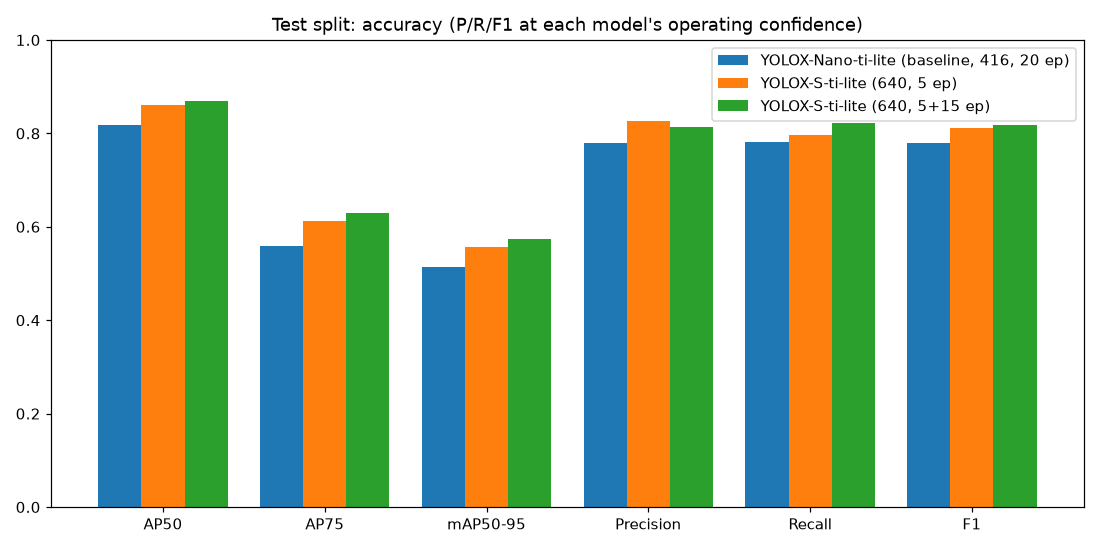

plots/comparison_e20_pr_false_alarms.png


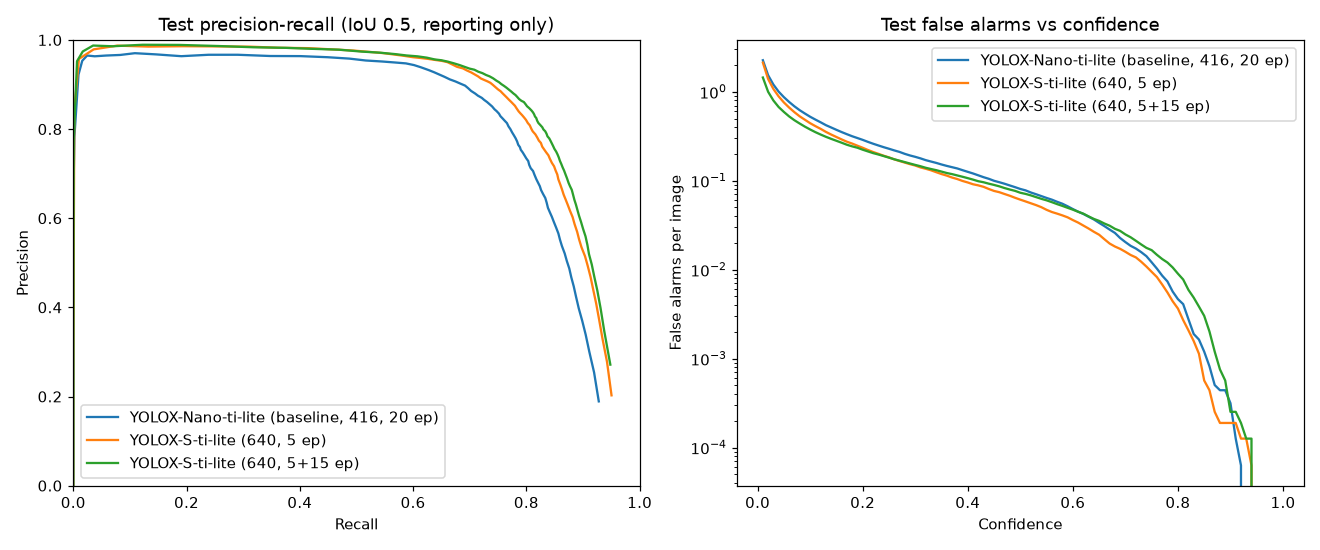

plots/e5p15/training_curves.png


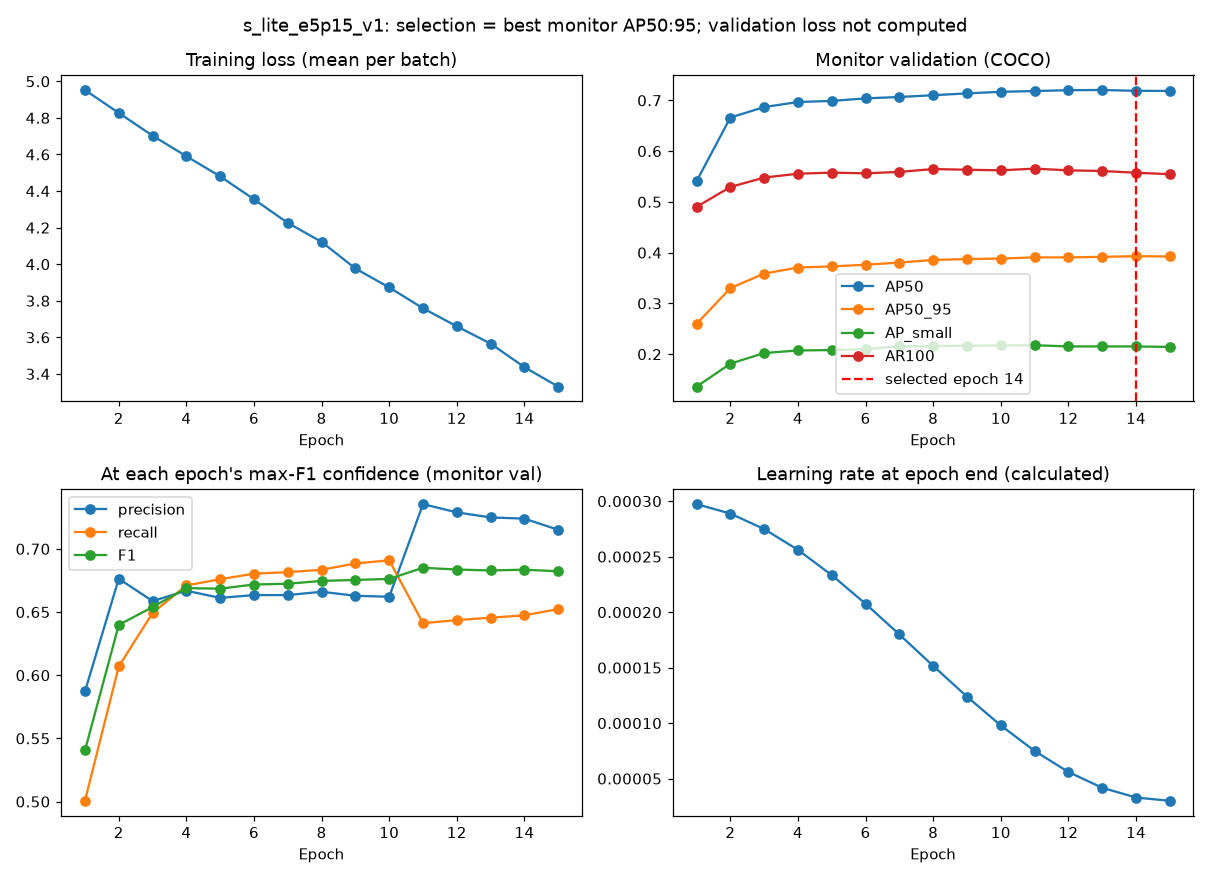

test/baseline_c040/curves.png


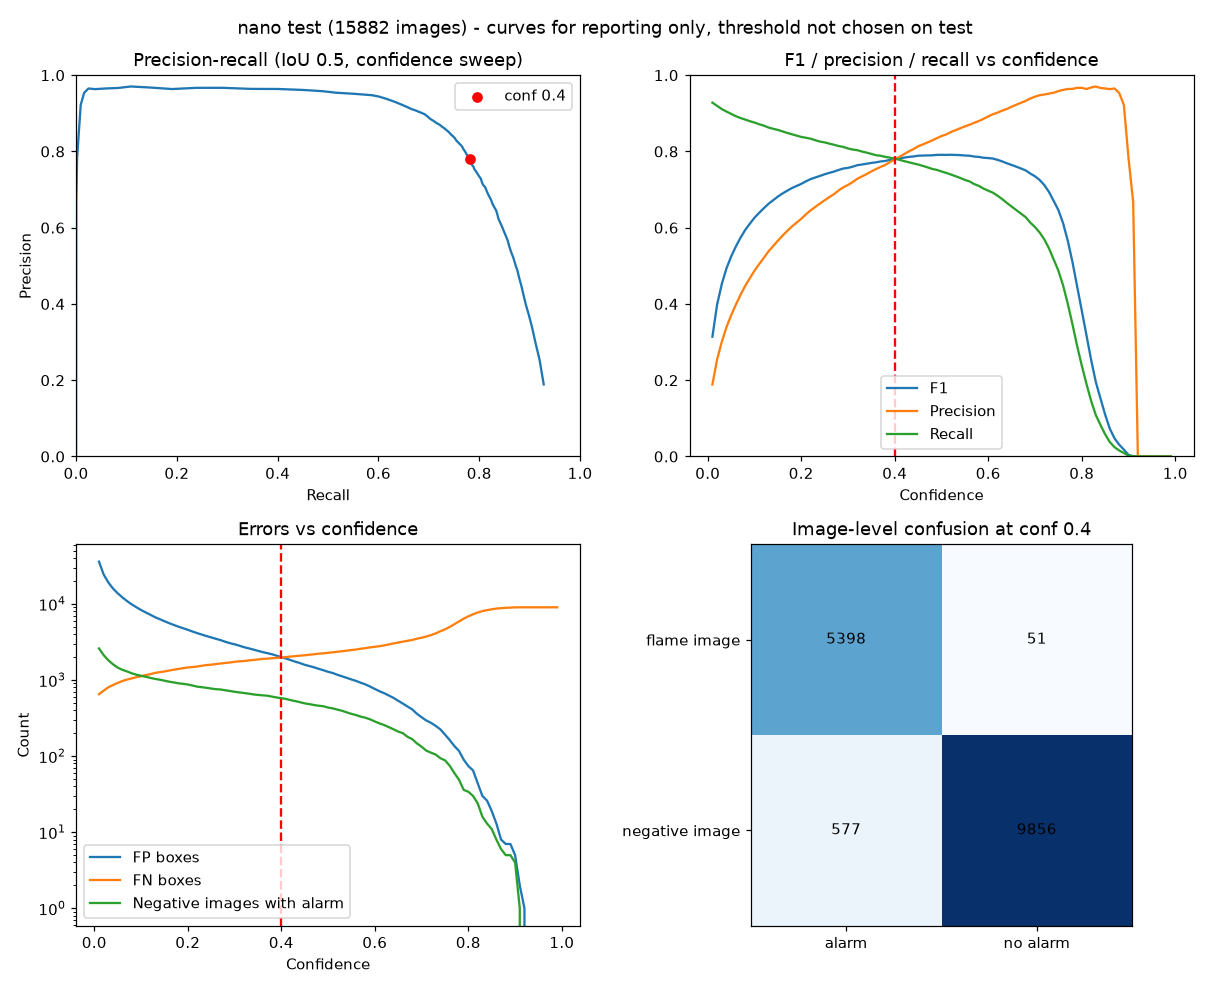

test/s_lite_e20_c040/curves.png


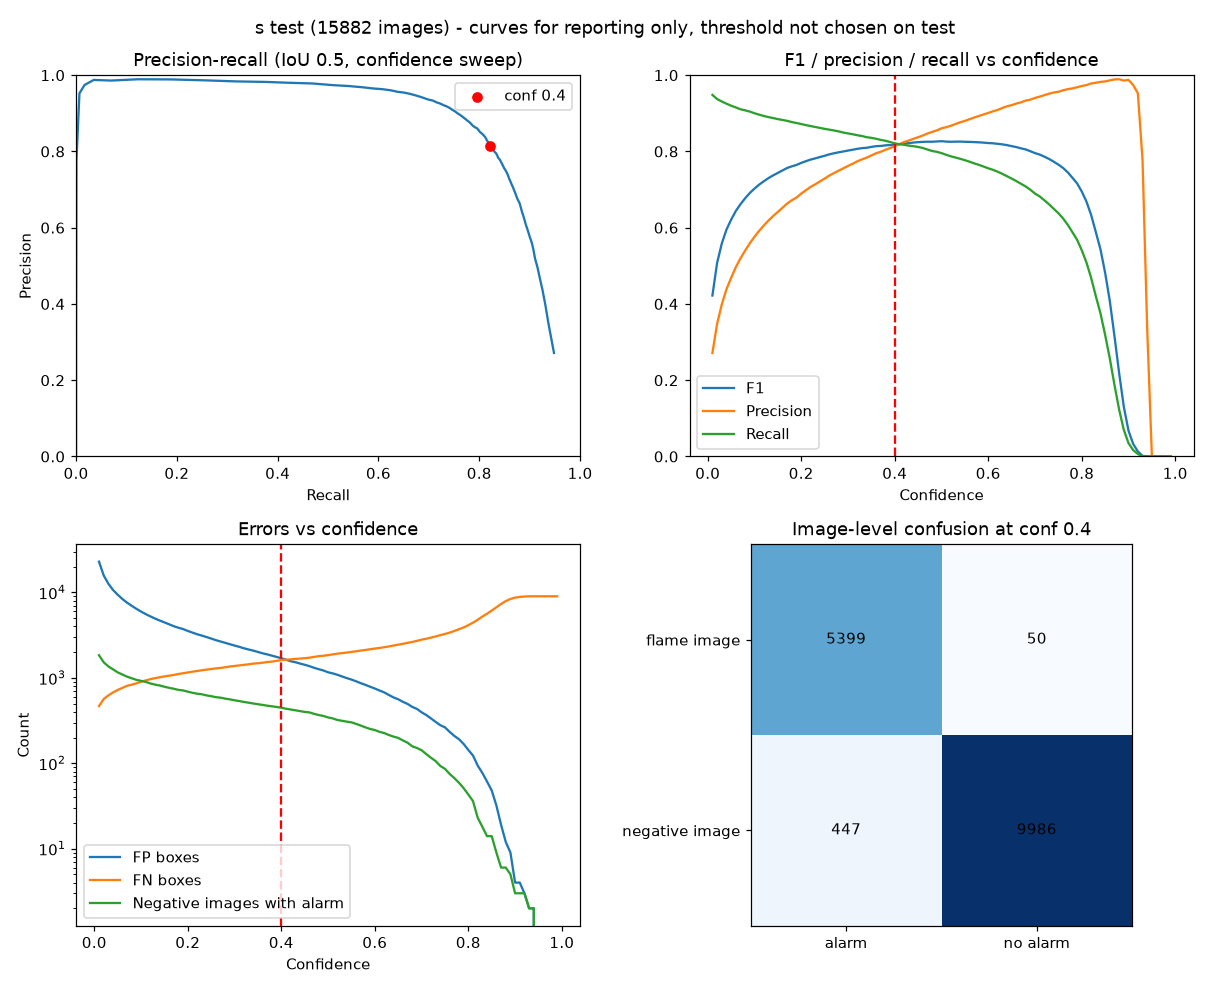

test/s_lite_e5_c040/curves.png


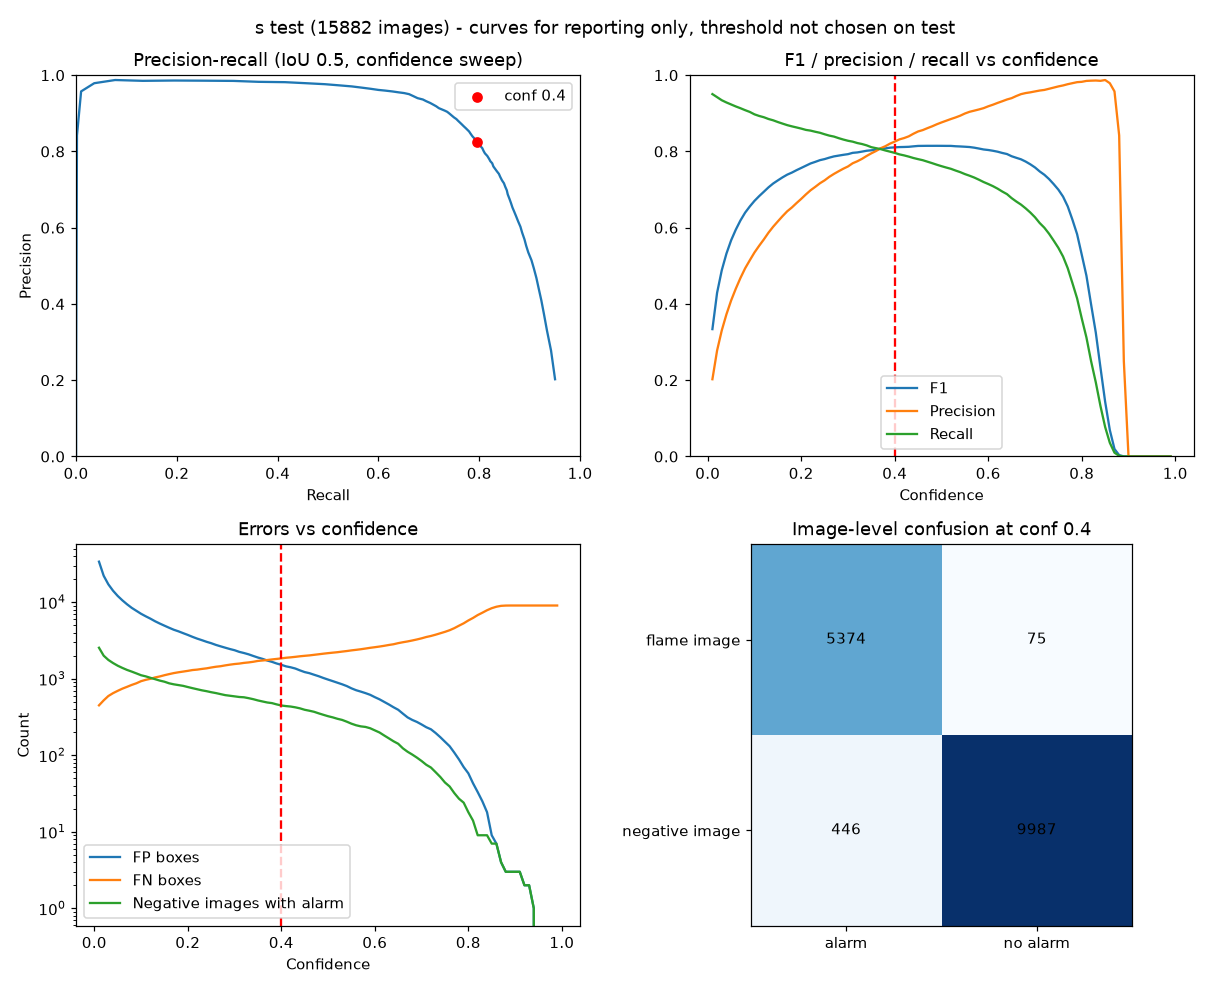

In [39]:
REPO = '/content/honeywell'
DRIVE_EXP = '/content/drive/MyDrive/HoneywellTraining/experiments/yolox_s_lite_flame'
LOG = f'{DRIVE_EXP}/logs/e5p15/pipeline.log'
PID = f'{DRIVE_EXP}/logs/e5p15/pipeline.pid'
import os, glob
from IPython.display import Image, Markdown, display
report = f'{DRIVE_EXP}/reports_e20/report.md'
if not os.path.exists(report):
    print('Not finished yet; see Cell 3.')
else:
    display(Markdown(open(report).read()))
    for picture in sorted(glob.glob(f'{DRIVE_EXP}/plots/comparison_e20_*.png')) + [f'{DRIVE_EXP}/plots/e5p15/training_curves.png'] + \
                   sorted(glob.glob(f'{DRIVE_EXP}/test/*_c040/curves.png')):
        if os.path.exists(picture):
            print(picture.replace(DRIVE_EXP + '/', '')); display(Image(picture))